![JohnSnowLabs](https://nlp.johnsnowlabs.com/assets/images/logo.png)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JohnSnowLabs/visual-nlp-workshop/blob/master/jupyter/deid-and-obfuscation/Obfuscation.ipynb)

In [1]:
license = ""
secret = ""
aws_access_key = ""
aws_secret_key = ""

version = secret.split("-")[0]
spark_ocr_jar_path = "../../../target/scala-2.12"

In [2]:
from sparkocr import start
import os
import sys

if license:
    os.environ['JSL_OCR_LICENSE'] = license
    os.environ['SPARK_NLP_LICENSE'] = license

if aws_access_key:
    os.environ['AWS_ACCESS_KEY'] = aws_access_key
    os.environ['AWS_SECRET_ACCESS_KEY'] = aws_secret_key

nlp_secret = ""

spark = start(jar_path=spark_ocr_jar_path, nlp_internal=True,
              nlp_secret=nlp_secret)

spark

Spark version: 3.5.0
Spark NLP version: 7.0.1
Spark NLP for Healthcare version: 7.0.1
Spark OCR version: 7.0.1


In [3]:
def write_pdf_to_disk(df, SAVE_OUTPUT_PDF):
  """
  df -> Result Dataframe from deid task.
  SAVE_OUTPUT_PDF -> Path to save output pdf.
  """

  import os

  os.makedirs(SAVE_OUTPUT_PDF, exist_ok=True)

  for row in df.select("path", "pdf").toLocalIterator():
    filename = row.asDict()["path"]
    basename = os.path.basename(filename).replace(".pdf", "")

    result_name = basename + "_result.pdf"

    savename = os.path.join(SAVE_OUTPUT_PDF, result_name)
    print(f"Saving File -> {savename}")

    pdfFile = open(savename, "wb")
    pdfFile.write(row.asDict()["pdf"])
    pdfFile.close()

In [4]:
# 📦 Spark OCR Imports
from sparkocr.transformers import *
from sparkocr.enums import *
from sparkocr.utils import *

# ⚡ Spark NLP Core
from sparknlp.base import *
from sparknlp.annotator import *
from sparknlp.pretrained import PretrainedPipeline

# 🔗 Spark ML
from pyspark.ml import Pipeline, PipelineModel
import pyspark.sql.functions as F

# 🧩 Spark NLP for Healthcare (JSL)
import sparknlp_jsl
from sparknlp_jsl.annotator import *

from IPython.display import display, Markdown

## 📄 PDF De-identification: Multi-Model Context Pipeline

This pretrained pipeline provides an **end-to-end solution**:

- **Input**: PDF `BinaryFile`  
- **Output**: PDF `BinaryFile`  

🔗 [pdf_deid_multi_model_context_pipeline](https://nlp.johnsnowlabs.com/2025/05/09/pdf_deid_multi_model_context_pipeline.html)

This pipeline is designed to **obfuscate Protected Health Information (PHI)** entities from PDF documents using a **multi-model, context-aware approach**.  

### ✨ Entities Obfuscated
- 🏥 **HOSPITAL**  
- 👤 **NAME**  
- 🧑‍⚕️ **PATIENT**  
- 🆔 **ID**  
- 📑 **MEDICALRECORD**  
- 🔢 **IDNUM**  
- 🌍 **COUNTRY**  
- 📍 **LOCATION**  
- 🏠 **STREET**  
- 🗺️ **STATE**  
- 📨 **ZIP**  
- 📞 **CONTACT / PHONE**  
- 📅 **DATE**  

In [5]:
obfuscation_pipeline = PretrainedPipeline("pdf_obfuscation_multi_model_context_pipeline", "en", "clinical/ocr")

pdf_obfuscation_multi_model_context_pipeline download started this may take some time.


Approx size to download 4.4 GB
pdf_obfuscation_multi_model_context_pipeline download started this may take some time.
Approximate size to download 4.4 GB
Download done! Loading the resource.


## PDF Inference with Spark

Here we are going to:

1. **Read PDF input** using Spark.  
2. **Convert it to Binary** format.  
3. **Call the pretrained pipeline** with the `transform()` call.  
4. **Use the `display_pdf` utility** to view the output PDF.
5. **Use the write_pdf_to_disk function** to save the results.

Using CPUs



    Image #0:
    Origin: file:/content/source_pdfs/Easy/PDF_Deid_Deidentification_0.pdf
    Resolution: 300 dpi
    Width: 2400 px
    Height: 3299 px
    Mode: 10
    Number of channels: 1


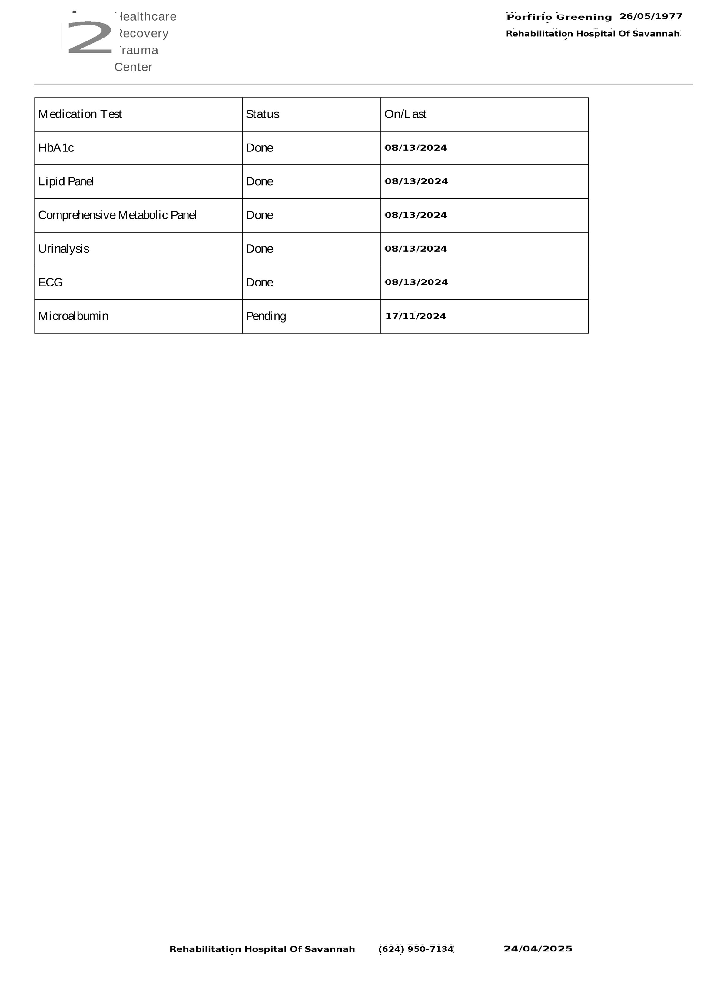


    Image #1:
    Origin: file:/content/source_pdfs/Easy/PDF_Deid_Deidentification_0.pdf
    Resolution: 300 dpi
    Width: 2400 px
    Height: 3299 px
    Mode: 10
    Number of channels: 1


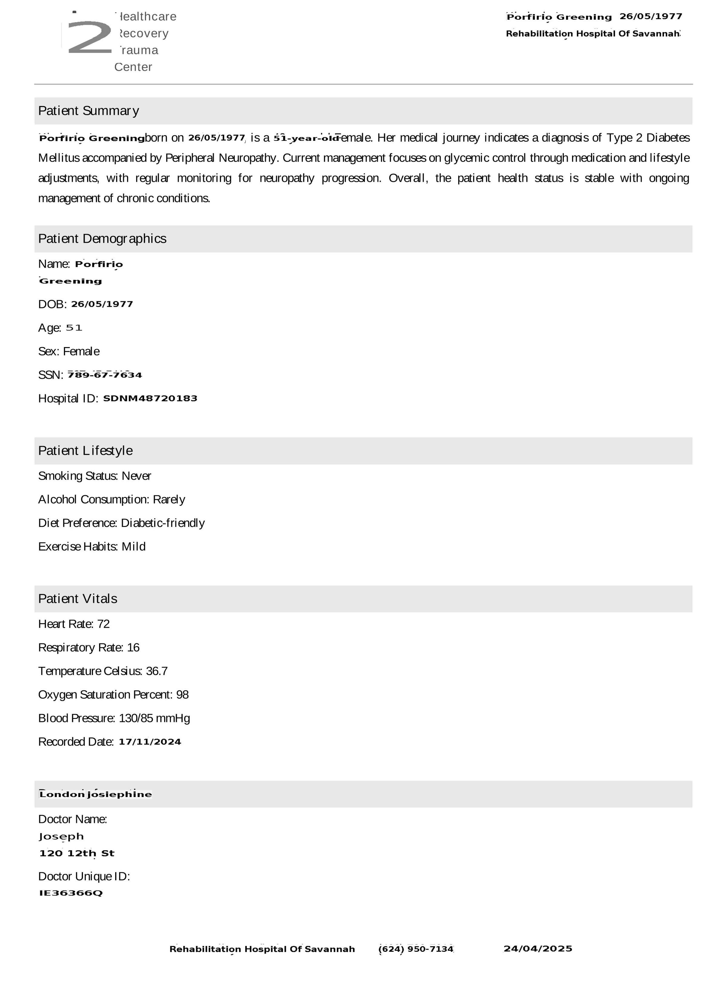


    Image #2:
    Origin: file:/content/source_pdfs/Easy/PDF_Deid_Deidentification_0.pdf
    Resolution: 300 dpi
    Width: 2400 px
    Height: 3299 px
    Mode: 10
    Number of channels: 1


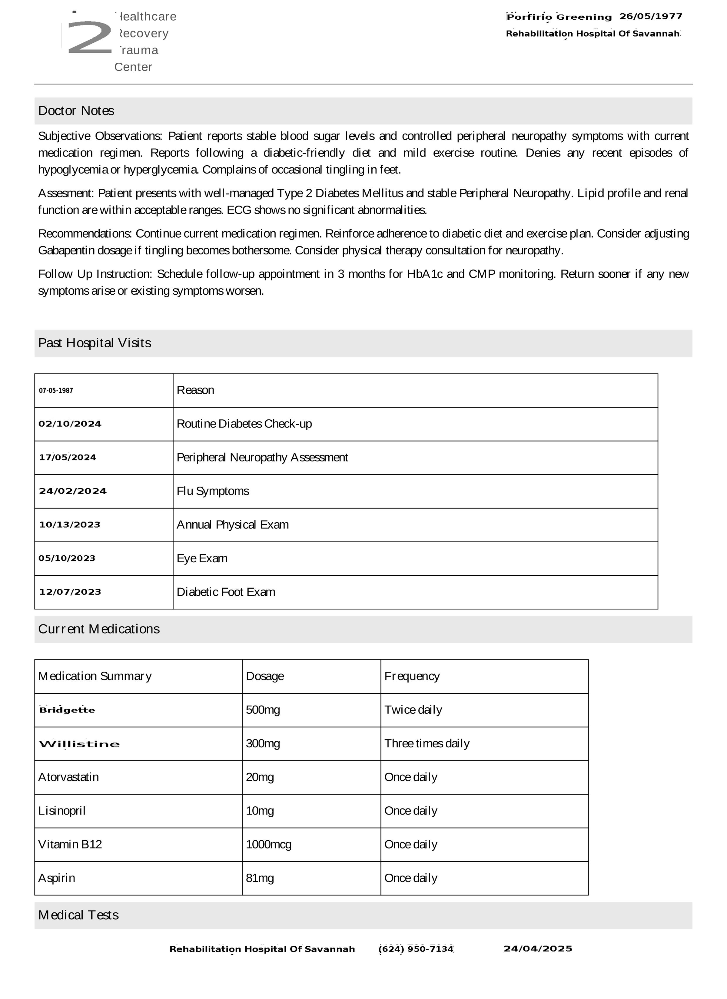

In [6]:
input_df = spark.read.format("binaryFile").load("./source_pdfs/Easy/PDF_Deid_Deidentification_0.pdf")

result = obfuscation_pipeline.transform(input_df).cache()

display_pdf(result, "pdf")

#write_pdf_to_disk(result, "/content/result")

In [7]:
obfuscation_pipeline.model.stages

[PdfToImage_3039dbc55d70,
 ImageToText_e47a60ca0cbf,
 DocumentAssembler_47aaa7f19fed,
 SentenceDetectorDLModel_6bafc4746ea5,
 REGEX_TOKENIZER_e1689c9bc262,
 WORD_EMBEDDINGS_MODEL_9004b1d00302,
 MedicalNerModel_9d4a08b1c03d,
 NerConverter_f230dec390db,
 CONTEXTUAL-PARSER_c654a34a3fa4,
 CONTEXTUAL-PARSER_33af26b2fdc0,
 CONTEXTUAL-PARSER_1b2769552347,
 CONTEXTUAL-PARSER_07bff3c2b284,
 CONTEXTUAL-PARSER_96b9d29769eb,
 CONTEXTUAL-PARSER_7aefd98e984c,
 ENTITY_EXTRACTOR_2ddfc4744b44,
 CONTEXTUAL-PARSER_99792b93398d,
 REGEX_MATCHER_2b137485db5e,
 CONTEXTUAL-PARSER_30dc43a095c1,
 CONTEXTUAL-PARSER_f64d354f0266,
 CONTEXTUAL-PARSER_72e20622d44a,
 CONTEXTUAL-PARSER_563cfd5f905d,
 REGEX_MATCHER_52d38a3643c9,
 MERGE_b0a322ec2787,
 MERGE_97a646c7a333,
 XLM_ROBERTA_EMBEDDINGS_b8a75c006754,
 MedicalNerModel_59183c57aedb,
 NER_CONVERTER_c48b64fa3415,
 PretrainedZeroShotNER_ca8c4dfe310f,
 NER_CONVERTER_1e400595b6da,
 PretrainedZeroShotNER_5f30ab9002f1,
 NER_CONVERTER_2eba5de8da64,
 MERGE_107935ba3a49,
 D

# 🔄 Obfuscation Pipeline Overview  

## 1. **PdfToImage** → *(First stage)*  
- Converts PDF pages into images.  
- **Default in pretrained pipeline:** grayscale.  
- **Customization:** overwritten to generate **colored images** instead.  

---

## 2. **Intermediate Visual Stages**  
- All **visual processing** runs directly on the images generated from PDFs.  

---

## 3. **DocumentAssembler** → *(Third stage)*  
- Serves as the entry point for **Healthcare NLP operations**.  

---

## 4. **Healthcare NLP Stages**  
- Perform **entity recognition** and **PHI detection**.  
- Results are consolidated in the **MERGE stage** *(sixth from bottom)*.  

## 5. **DeIdentification NLP Stages**  
- Perform **obfuscation** and **PHI detection**.  
- Generates a mapping between the obfuscated and original PHI.
---

## 5. **Visual Stages (Post-NLP)**  

### 🔹 PositionFinder  
- **Input:** `CHUNK`, `POSITIONS`
- **Output:** Coordinates (regions containing PHI).  
- **Params:**  
  - `smoothCoordinates`: Improves boundary alignment and avoids clipping nearby non-PHI text.  

### 🔹 ImageDrawRegions (Obfuscation)  
- **Input:** `Image + Coordinates + CHUNK`  
- **Output:** Obfuscated image  
- **Params:**  
  - `patchImage = True` → performs **obfuscation** (not redaction).  

---

## 6. **ImageToPDF** → *(Final stage)*  
- Converts processed images back into a PDF.  
- **Note:** This is an **aggregation stage**, which discards intermediate results.  
- **Customization:** remove this stage to inspect intermediate outputs.  

---

# ⚙️ Customization Notes  
- `deid_pipeline.model.stages[:-3]`  
  - Keeps all stages except the **last three**.  

- `stages[0] = pdf_to_image`  
  - Replaces the original **PdfToImage** with a new one (e.g., for colored image extraction).  

---

In [8]:
stages = obfuscation_pipeline.model.stages[:-3].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = PipelineModel(stages=stages)

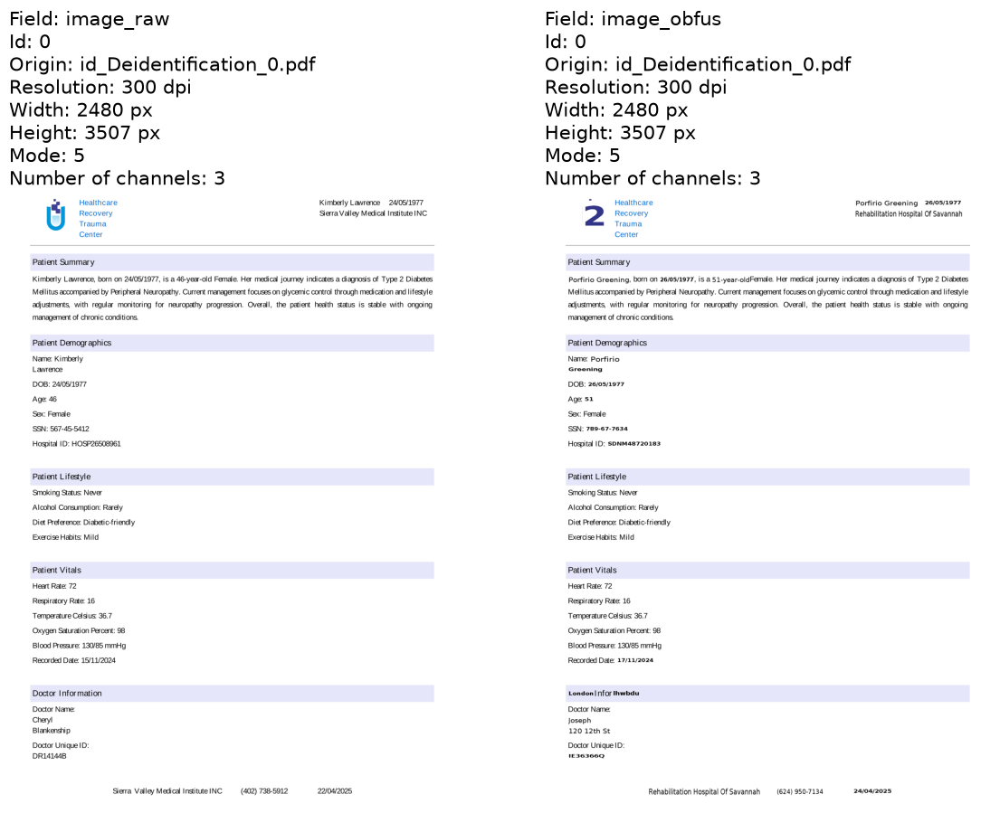

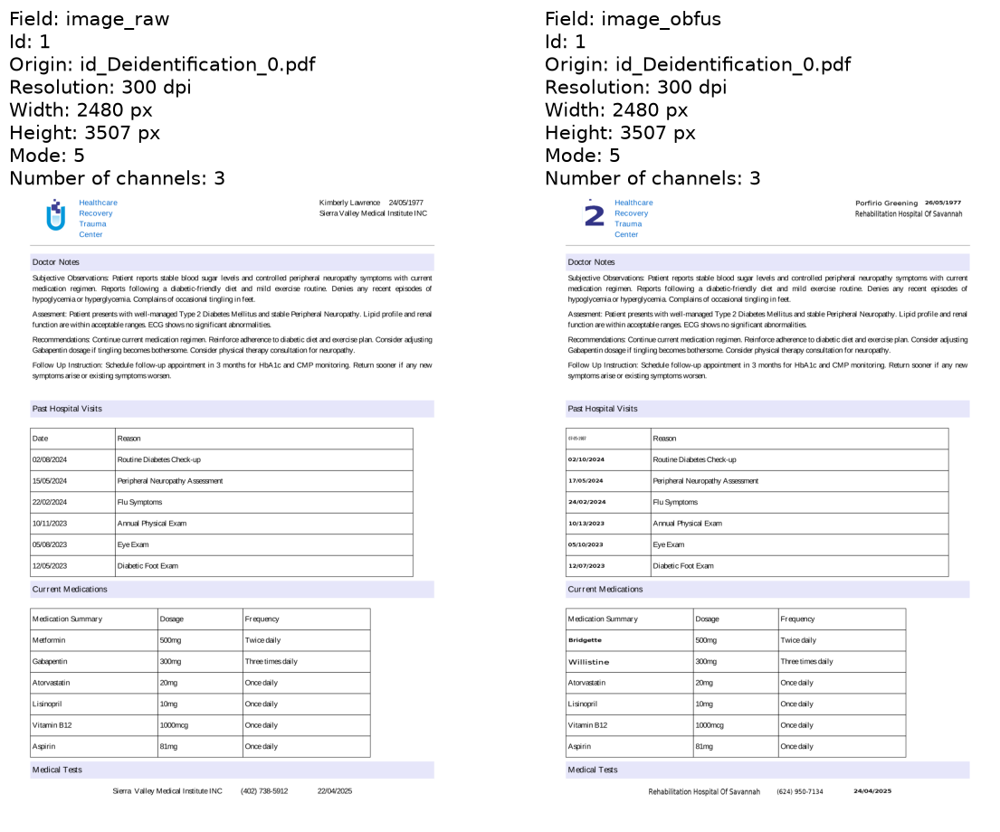

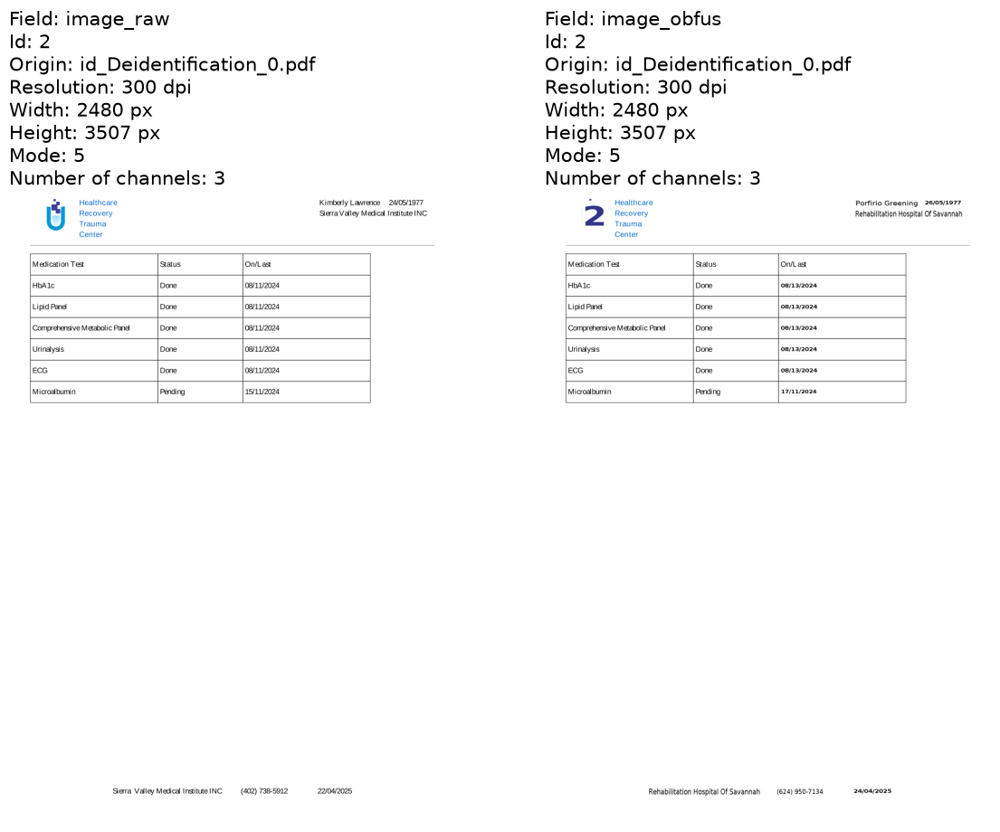

In [9]:
result = obfuscation_updated_pipeline.transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

In [10]:
# View the final results
# ObfuscatedResult - Output from DeIdentification Stage
# ObfuscatedLength - Length of Obfuscated Text
# DetectedPhi - Original Text detected as PHI by NER Stages
# OriginalLength - Length of Original Text
# LengthOffSet - Absolute difference between ObfuscatedText length and Detected Phi Text Length
# EntityClass - Entity type detected by NER stages

result.withColumn("res", F.explode(F.col("new_aux"))) \
    .select(F.col("res.result").alias("ObfuscatedResult"),
            F.length("res.result").alias("ObfuscatedLength"),
            F.col("res.metadata.originalChunk").alias("DetectedPhi"),
            F.length("res.metadata.originalChunk").alias("OriginalLength"),
            F.abs(F.col("ObfuscatedLength") - F.col("OriginalLength")).alias("LengthOffset"),
            F.col("res.metadata.entity").alias("EntityClass"),
            F.col("pagenum")) \
    .orderBy("pagenum").show(100, False)

+-----------------------------------+----------------+-----------------------------------+--------------+------------+-----------+-------+
|ObfuscatedResult                   |ObfuscatedLength|DetectedPhi                        |OriginalLength|LengthOffset|EntityClass|pagenum|
+-----------------------------------+----------------+-----------------------------------+--------------+------------+-----------+-------+
|Porfirio Greening                  |17              |Kimberly Lawrence                  |17            |0           |PATIENT    |0      |
|26/05/1977                         |10              |24/05/1977                         |10            |0           |DATE       |0      |
|Rehabilitation Hospital Of Savannah|35              |Sierra Valley Medical Institute INC|35            |0           |HOSPITAL   |0      |
|2                                  |1               |0                                  |1             |0           |IDNUM      |0      |
|Porfirio Greening         

# 🏷️ Logo Detection before OCR

The **"0"** above is not text: OCR reads the **logo** as a character and the NER stages tag it as **IDNUM**, so a fake value is drawn over the logo.

**`ImageLogoDetector`** finds the logos before OCR, and the existing stages do the rest:

- **`ImageDrawRegions`** (filled white rectangles) masks the logos → `image_no_logo`.
- **`ImageToText`** runs on `image_no_logo`, so the logo never reaches the NER stages.
- The final **`ImageDrawRegions`** draws over `image_raw`, so the logos stay untouched in the output.

The masked image has the same size as the original, so the coordinates are valid on both.

In [11]:
logo_detector = ImageLogoDetector.pretrained("logo_detector_v1", "en", "clinical/ocr") \
  .setInputCol("image_raw") \
  .setOutputCol("logo_regions")

mask_logos = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("logo_regions") \
  .setFilledRect(True) \
  .setRectColor(Color.white) \
  .setOutputCol("image_no_logo")

ocr_no_logo = obfuscation_pipeline.model.stages[1].copy() \
  .setInputCol("image_no_logo")

stages = obfuscation_pipeline.model.stages[:-3].copy()

stages[0] = pdf_to_image
stages[1:2] = [logo_detector, mask_logos, ocr_no_logo]
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_logo_pipeline = PipelineModel(stages=stages)

logo_detector_v1 download started this may take some time.


Approximate size to download 31.6 MB
logo_detector_v1 download started this may take some time.
Approximate size to download 31.6 MB
Download done! Loading the resource.


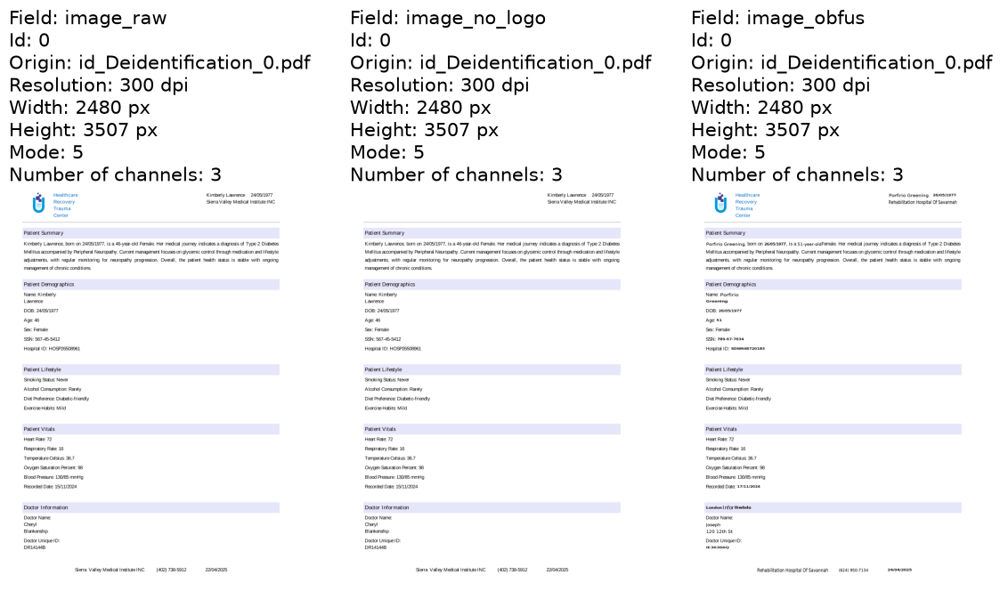

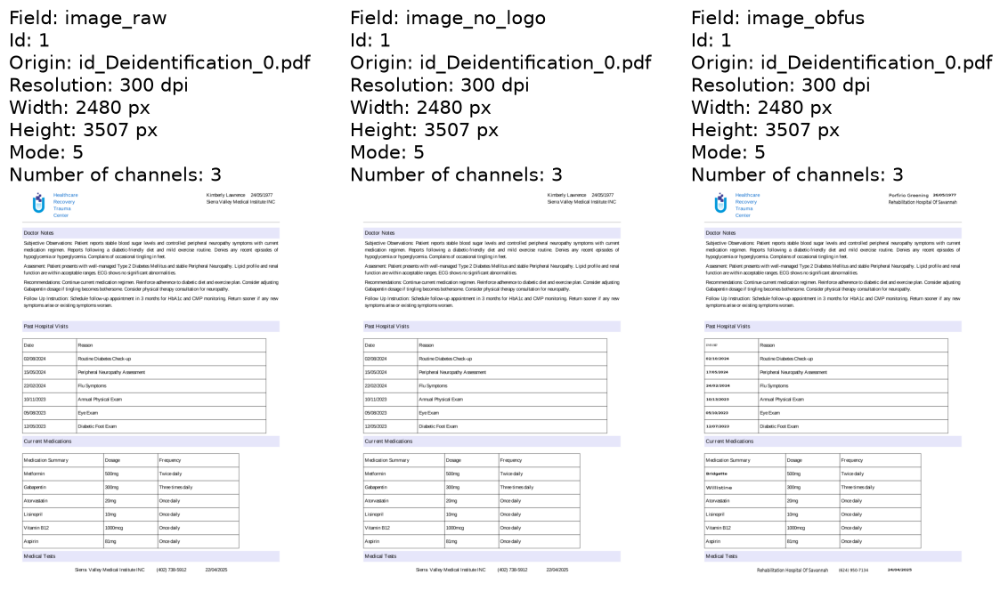

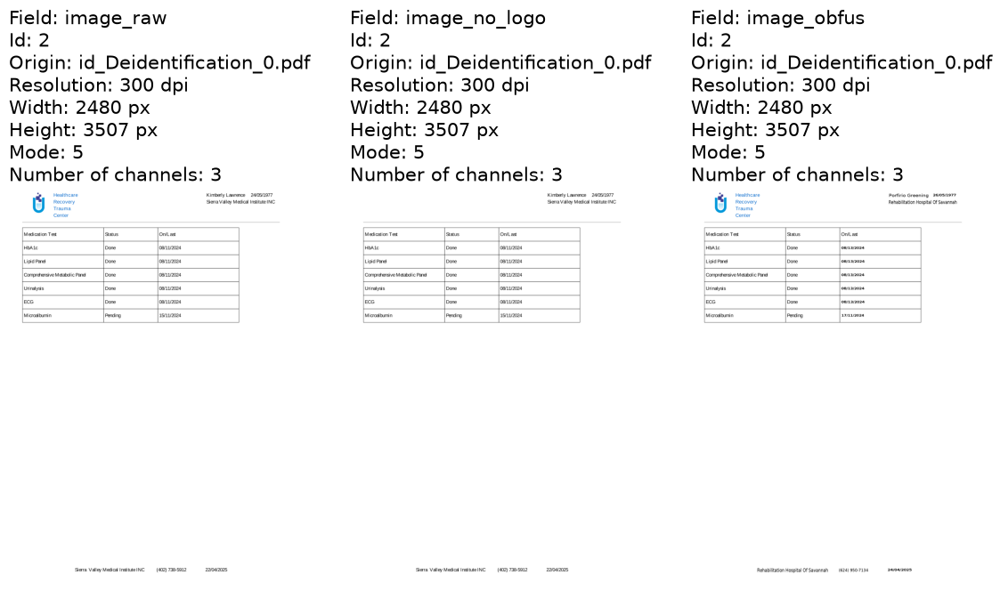

In [12]:
result = obfuscation_logo_pipeline.transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_no_logo,image_obfus")

In [13]:
result.withColumn("res", F.explode(F.col("new_aux"))) \
    .select(F.col("res.result").alias("ObfuscatedResult"),
            F.length("res.result").alias("ObfuscatedLength"),
            F.col("res.metadata.originalChunk").alias("DetectedPhi"),
            F.length("res.metadata.originalChunk").alias("OriginalLength"),
            F.abs(F.col("ObfuscatedLength") - F.col("OriginalLength")).alias("LengthOffset"),
            F.col("res.metadata.entity").alias("EntityClass"),
            F.col("pagenum")) \
    .orderBy("pagenum").show(100, False)

+-----------------------------------+----------------+-----------------------------------+--------------+------------+-----------+-------+
|ObfuscatedResult                   |ObfuscatedLength|DetectedPhi                        |OriginalLength|LengthOffset|EntityClass|pagenum|
+-----------------------------------+----------------+-----------------------------------+--------------+------------+-----------+-------+
|Porfirio Greening                  |17              |Kimberly Lawrence                  |17            |0           |PATIENT    |0      |
|26/05/1977                         |10              |24/05/1977                         |10            |0           |DATE       |0      |
|Rehabilitation Hospital Of Savannah|35              |Sierra Valley Medical Institute INC|35            |0           |HOSPITAL   |0      |
|Porfirio Greening                  |17              |Kimberly Lawrence                  |17            |0           |PATIENT    |0      |
|26/05/1977                

The logo is no longer read as **"0"**, so there is no fake **IDNUM** over it.

If the logos have to be removed too, add one more `ImageDrawRegions` over `image_obfus` with `logo_regions`, `setFilledRect(True)` and the rectangle color you need.

# 🔎 OCR & NER Observations  

- The **OCR stage** is mistakenly detecting the **logo** as the character **"0"**.  
- The **NER stages** are classifying this as an **IDNUM**.  
- ✅ Solved above with **`ImageLogoDetector`**: the logos are masked before OCR (the next pipelines include it).  

- **Medications** like **Metformin** and **Gabapentin** are being classified as **NAMES**.  
  - While this is technically not incorrect, these entities should **not** be kept in the final output.  

- **Date** is being classified as **DATE**.  
  - This is correct, but we will filter these out for our use case.  

---

# ⚙️ Deidentification Stage Behavior  

The **Deidentification stage** takes input sentence/document, tokens, and CHUNKS.  
In **obfuscation mode**, these parameters can be configured:

- **`setObfuscateDate`** → obfuscate Dates as well  
- **`setKeepMonth`** → keep the Date Month unchanged  
- **`setKeepYear`** → keep the Date Year unchanged  
- **`setDays`** → set the date offset  
- **`setRegion`** → specify date format according to region  

- **`setKeepTextSizeForObfuscation`** → maintain the same text size in the obfuscated result  
- **`setFakerLengthOffset`** → set a max length offset when lengths don’t match (for special cases)  

- **`setConsistentObfuscation`** → ensures consistent handling across pages (e.g., if NAME is missed in page 2, regex can catch it)  
- **`setChunkMatching`** → define entity type and prediction threshold for regex matching when using consistent obfuscation  

---

# 🛠️ Solution  

We can use the **[`ChunkFilterer`](https://www.johnsnowlabs.com/refining-entity-detection-in-healthcare-nlp-precision-through-entity-filtering/)** stage to **remove irrelevant entities**:  

✅ Ensures only relevant PHI entities are passed forward in the pipeline.  

---

#  Additional Resource  

- **Clinical De-Identification Notebook**:  
  [JohnSnowLabs Spark NLP Workshop – Clinical De-Identification](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Healthcare/4.Clinical_DeIdentification.ipynb)  

---

# 📚 References  

- Blog: [Refining Entity Detection in Healthcare NLP – Precision through Entity Filtering](https://www.johnsnowlabs.com/refining-entity-detection-in-healthcare-nlp-precision-through-entity-filtering/)  
- Notebook: [ChunkFilterer Example (Spark NLP Workshop)](https://github.com/JohnSnowLabs/spark-nlp-workshop/blob/master/Spark_NLP_Udemy_MOOC/Healthcare_NLP/ChunkFilterer.ipynb)  

In [14]:
matcherWhitelist = {
 'HOSPITAL': 0.9,
 'NAME': 0.6,
 'PATIENT': 0.9,
 'ID': 0.9,
 'MEDICALRECORD': 0.6,
 'IDNUM': 0.6,
 'COUNTRY': 0.9,
 'LOCATION': 0.9,
 'STREET': 0.9,
 'STATE': 0.9,
 'ZIP': 0.9,
 'CONTACT': 0.9,
 'PHONE': 0.9,
 'DATE': 0.9
}

In [15]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["Date", "Gabapentin", "Metformin"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages[1:2] = [logo_detector, mask_logos, ocr_no_logo]
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

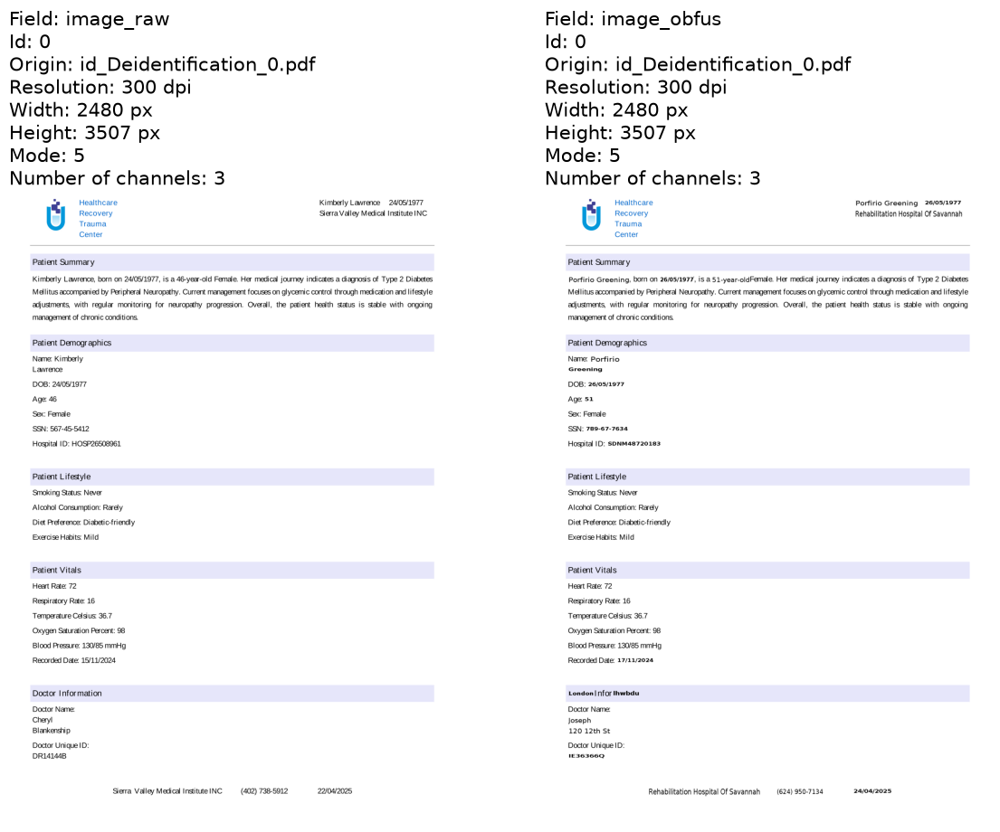

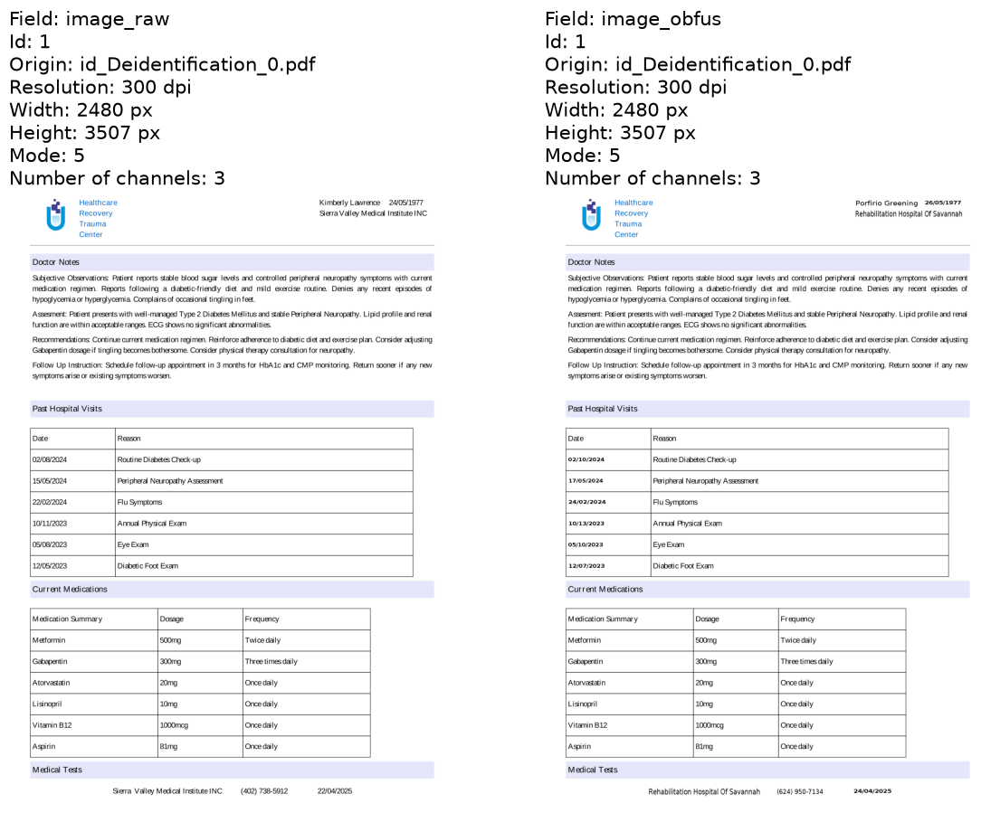

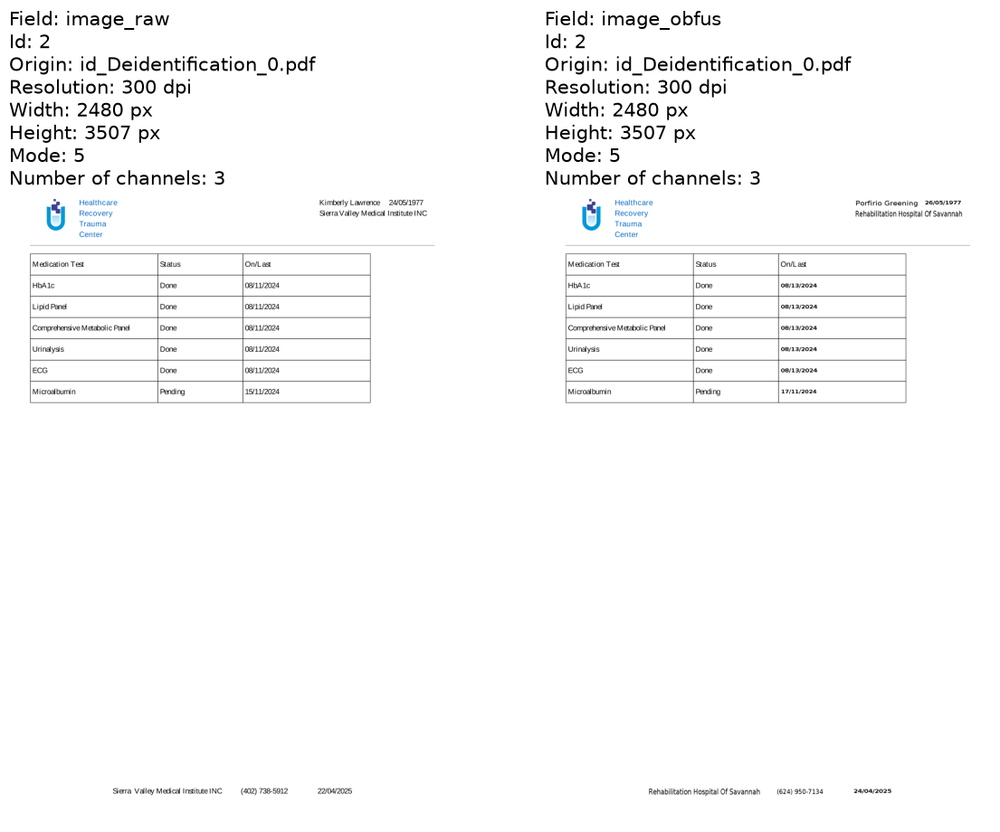

In [16]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

In [17]:
obfuscation_mapping = result.withColumn("res", F.explode(F.col("new_aux"))) \
    .select(F.col("res.result").alias("ObfuscatedResult"),
            F.length("res.result").alias("ObfuscatedLength"),
            F.col("res.metadata.originalChunk").alias("DetectedPhi"),
            F.length("res.metadata.originalChunk").alias("OriginalLength"),
            F.abs(F.col("ObfuscatedLength") - F.col("OriginalLength")).alias("LengthOffset"),
            F.col("res.metadata.entity").alias("EntityClass"),
            F.col("pagenum")) \
    .orderBy("pagenum")

obfuscation_mapping.show(100, False)

+-----------------------------------+----------------+-----------------------------------+--------------+------------+-----------+-------+
|ObfuscatedResult                   |ObfuscatedLength|DetectedPhi                        |OriginalLength|LengthOffset|EntityClass|pagenum|
+-----------------------------------+----------------+-----------------------------------+--------------+------------+-----------+-------+
|Porfirio Greening                  |17              |Kimberly Lawrence                  |17            |0           |PATIENT    |0      |
|26/05/1977                         |10              |24/05/1977                         |10            |0           |DATE       |0      |
|Rehabilitation Hospital Of Savannah|35              |Sierra Valley Medical Institute INC|35            |0           |HOSPITAL   |0      |
|Porfirio Greening                  |17              |Kimberly Lawrence                  |17            |0           |PATIENT    |0      |
|26/05/1977                

In [18]:
# Create a Mapping of Obfuscated->Original Value, use Pandas to export easily.
pandas_df = obfuscation_mapping.toPandas()

pandas_df.head(20)

,ObfuscatedResult,ObfuscatedLength,DetectedPhi,OriginalLength,LengthOffset,EntityClass,pagenum
0,Porfirio Greening,17,Kimberly Lawrence,17,0,PATIENT,0
1,26/05/1977,10,24/05/1977,10,0,DATE,0
2,Rehabilitation Hospital Of Savannah,35,Sierra Valley Medical Institute INC,35,0,HOSPITAL,0
3,Porfirio Greening,17,Kimberly Lawrence,17,0,PATIENT,0
4,26/05/1977,10,24/05/1977,10,0,DATE,0
5,51-year-old,11,46-year-old,11,0,AGE,0
6,Porfirio,8,Kimberly,8,0,PATIENT,0
7,Greening,8,Lawrence,8,0,PATIENT,0
8,26/05/1977,10,24/05/1977,10,0,DATE,0
9,51,2,46,2,0,AGE,0


# ✍️ ImageDrawRegions – Font Handling  

The **`ImageDrawRegions`** stage allows customizing text rendering during drawing operations.  

### 🔤 Fonts  

- Use **`setFontName`** to specify the font.  
- The font must be:
  - Available on your system **OR**  
  - Part of the **Java Standard Fonts**.  

👉 If the specified font is not found, the stage will **fall back to defaults**.  
You can confirm this by **checking the logs**.  

### 🎨 Font Styles  

- Supported styles include:  
  - **Plain**  
  - **Bold**  
  - **Auto**  

In [19]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["Date", "Gabapentin", "Metformin"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(True) \
  .setFontStyle(FontStyle.BOLD) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages[1:2] = [logo_detector, mask_logos, ocr_no_logo]
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

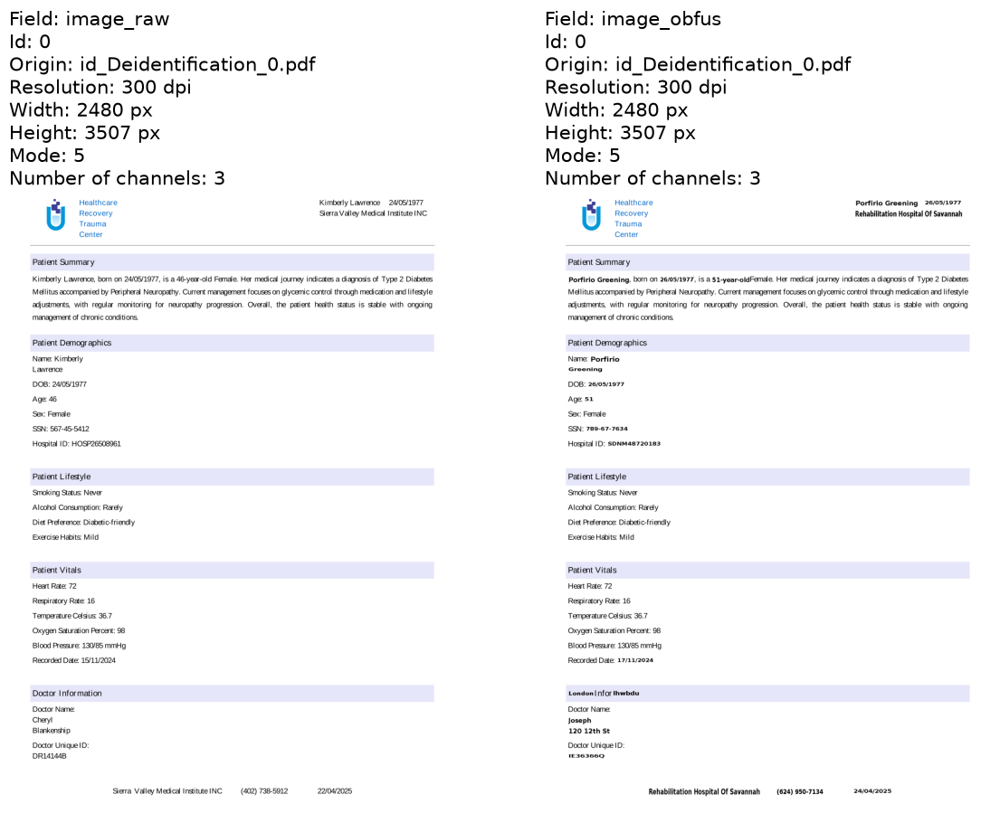

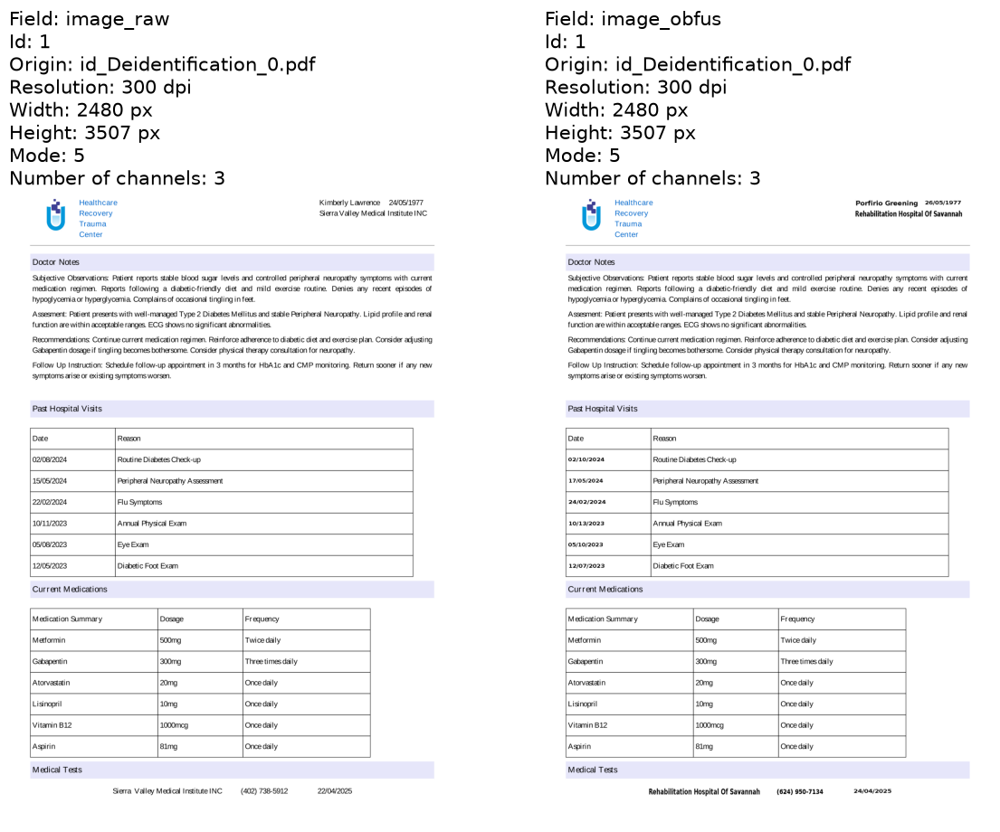

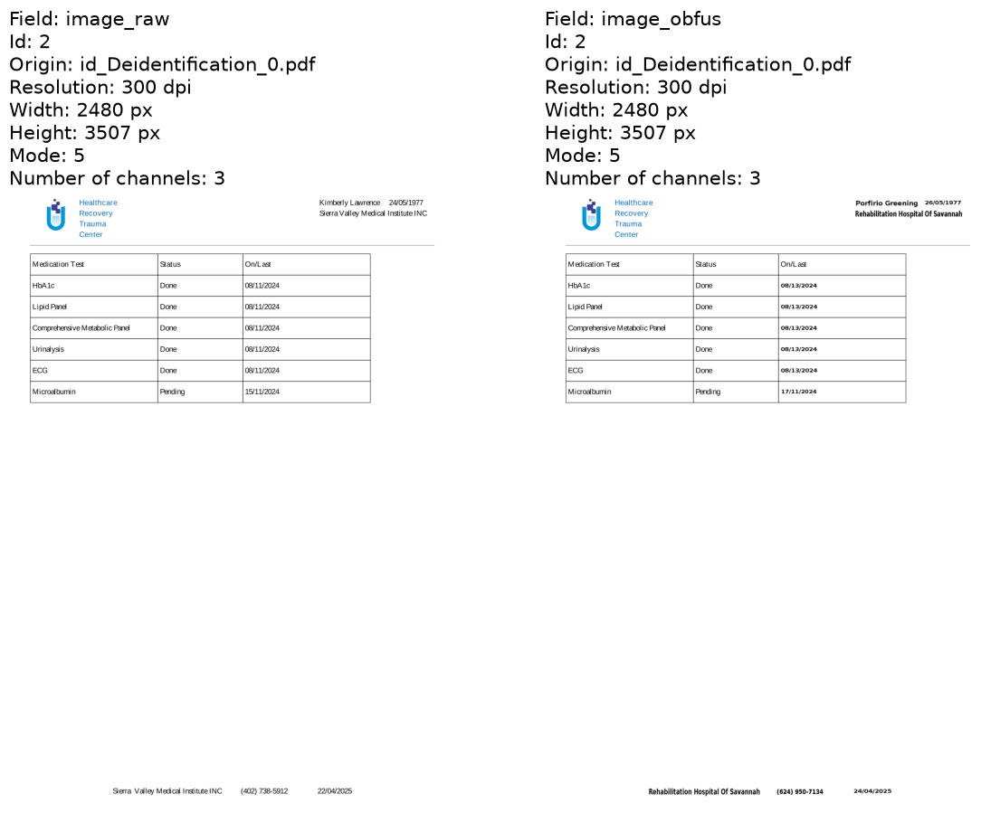

In [20]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

# 🖼️ ImageDrawRegions – Color Settings  

The **`ImageDrawRegions`** stage supports customizing **text** and **background colors** when drawing patches.  

### 🎨 Color Configuration  
- **`setPatchImages(True)`** → enable patch-based rendering  
- **`setPatchTextColor`** → set the text color inside the patch  
- **`setPatchBackgroundColor`** → set the background color for the patch  

⚠️ **Important**:  
You must set **`setDynamicColor(False)`** in order for these custom colors to take effect.  
Otherwise, the stage will automatically choose colors dynamically.

In [21]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["Date", "Gabapentin", "Metformin"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setFontStyle(FontStyle.PLAIN) \
  .setDynamicColor(False) \
  .setPatchBackgroundColor(Color.yellow) \
  .setPatchTextColor(Color.red) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages[1:2] = [logo_detector, mask_logos, ocr_no_logo]
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

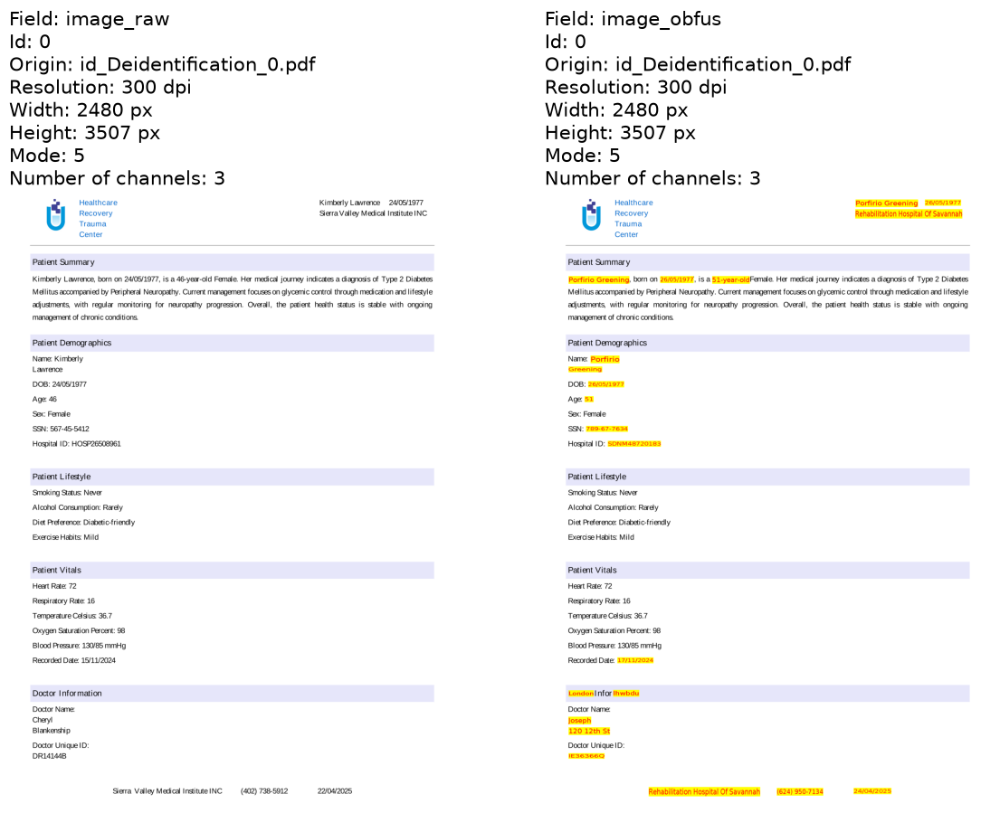

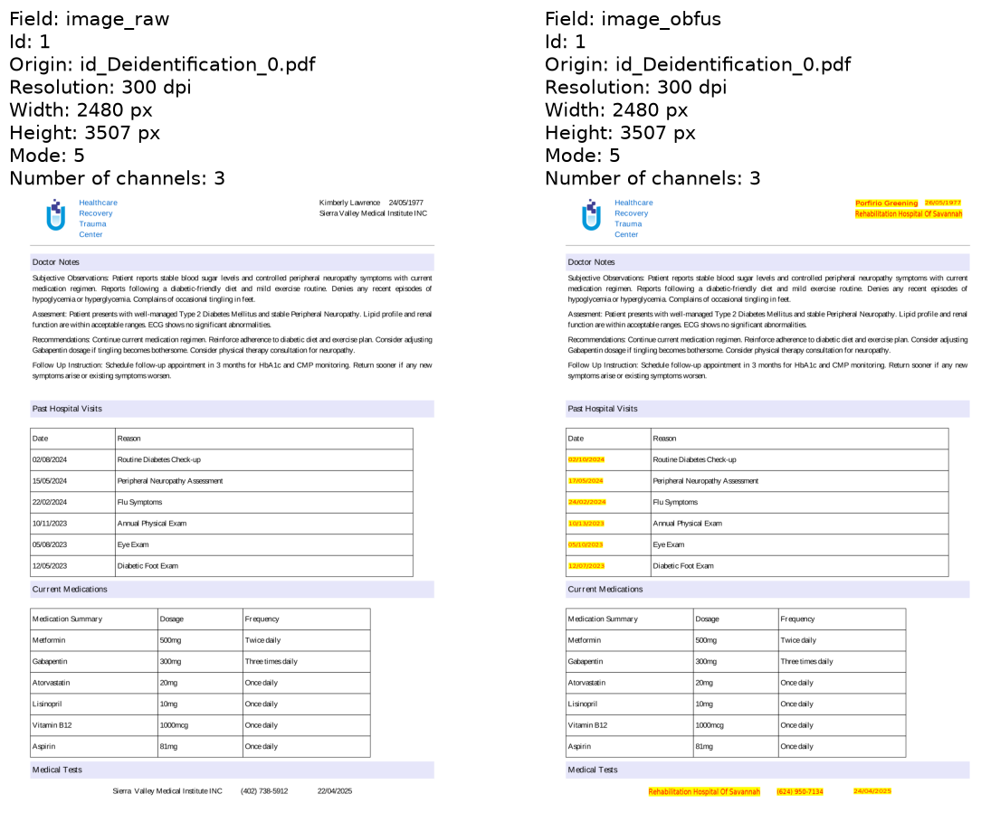

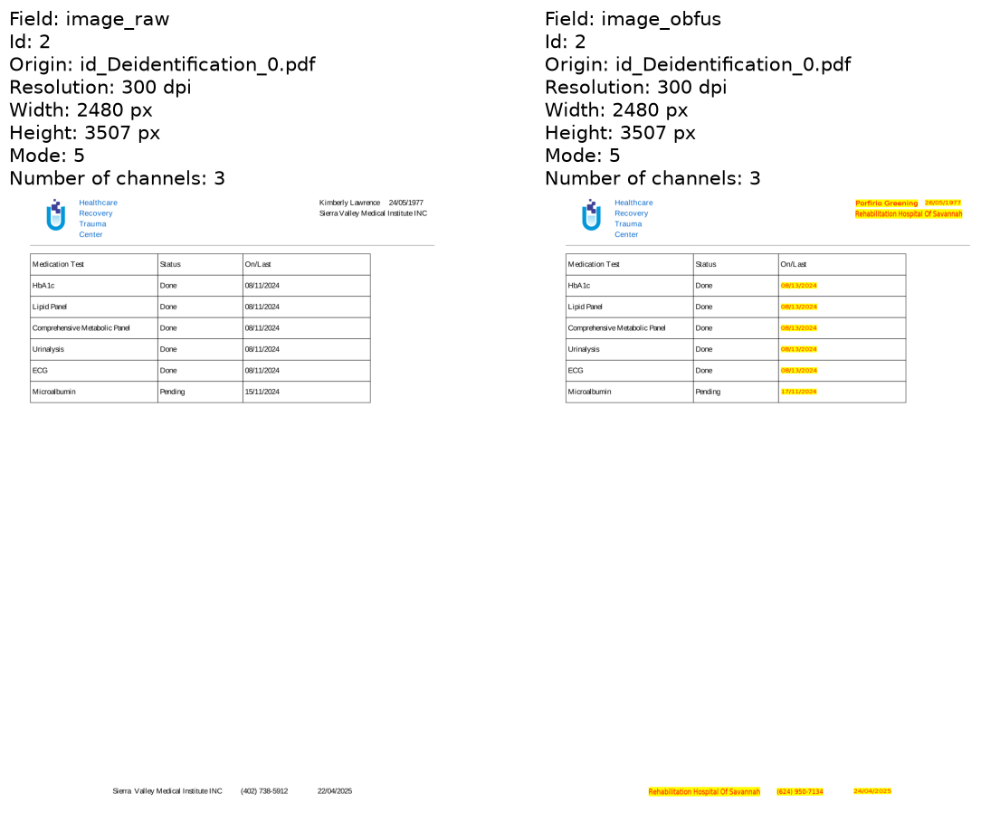

In [22]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

## 🔒 Redaction & Obfuscation Together  

You can combine **deidentification** and **obfuscation** in the same stage:  

- **`setPatchImages(True)`** → enable patch-based rendering  
- **`setRedactionEntityList([...])`** → specify entity types to **redact**  
- **Other entities** will be **obfuscated**  
- **`setRectColor`** → specify rectangle color for redaction  

---

In [23]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["Date", "Gabapentin", "Metformin"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(False) \
  .setPatchBackgroundColor(Color.yellow) \
  .setPatchTextColor(Color.red) \
  .setRedactionEntityList(["DATE", "NAME"]) \
  .setRectColor(Color.red) \
  .setFontStyle(FontStyle.PLAIN) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages[1:2] = [logo_detector, mask_logos, ocr_no_logo]
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

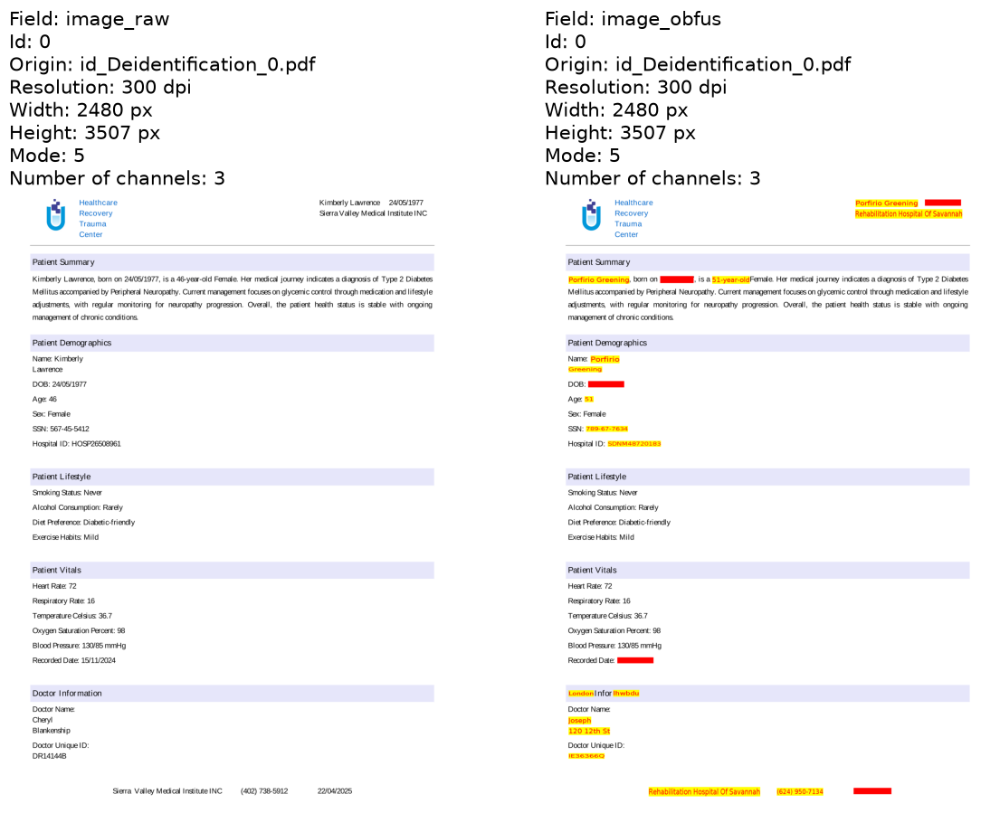

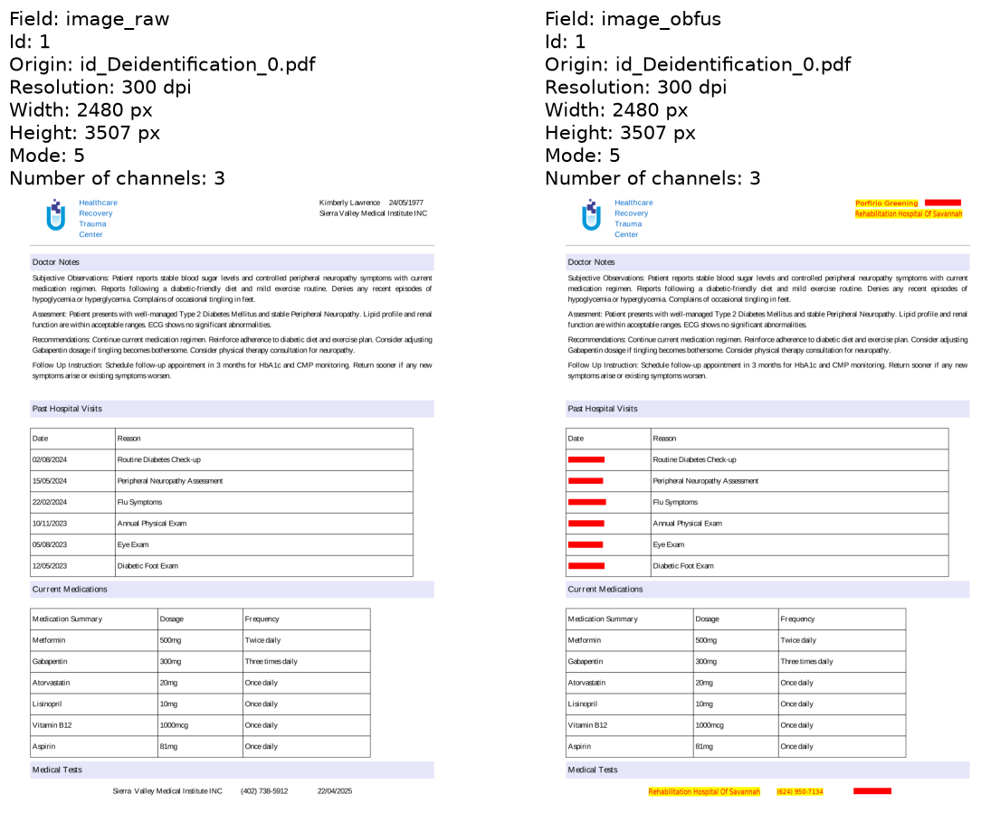

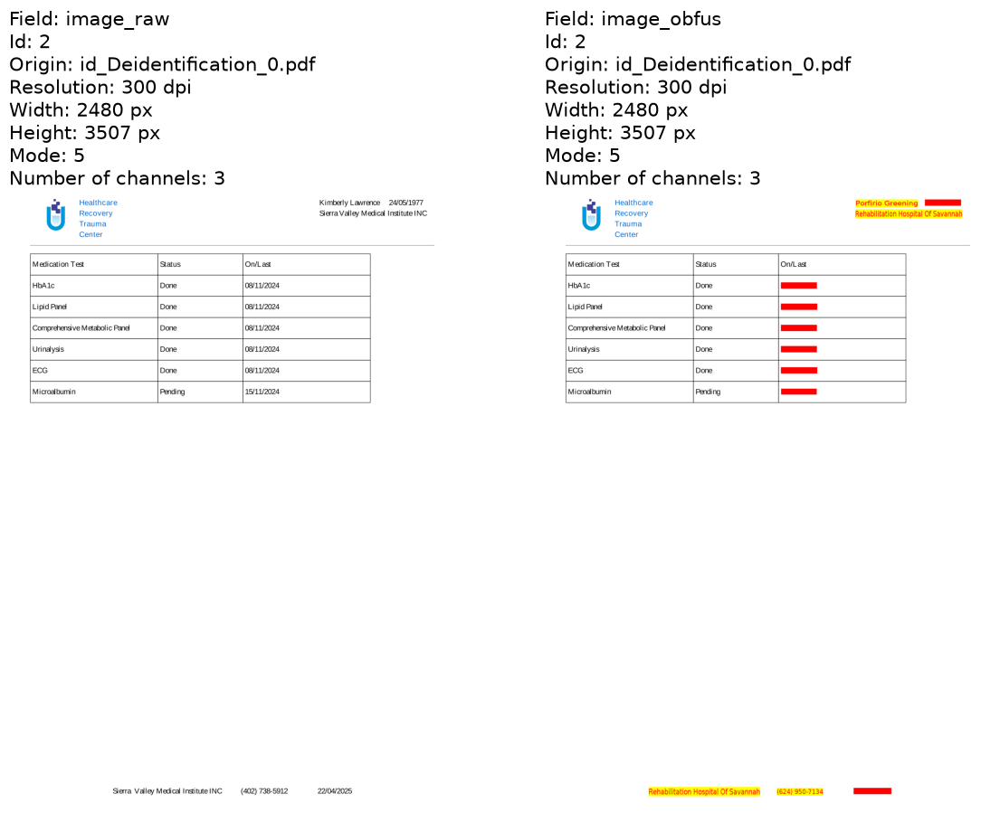

In [24]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

## 🚫 Blacklist Support  

- **`setBlackList([...])`** → specify entity types to **ignore completely** (no redaction or obfuscation).  
- Must be used along with **`setPatchImages(True)`**.  
- ⚠️ **Do not include the same entity in both `setRedactionEntityList` and `setBlackList`**, otherwise it will cause conflicts.  


In [25]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["Date", "Gabapentin", "Metformin"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(False) \
  .setPatchBackgroundColor(Color.yellow) \
  .setPatchTextColor(Color.red) \
  .setBlackList(["PHONE", "AGE"]) \
  .setRedactionEntityList(["DATE", "NAME"]) \
  .setRectColor(Color.red) \
  .setFontStyle(FontStyle.PLAIN) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages[1:2] = [logo_detector, mask_logos, ocr_no_logo]
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

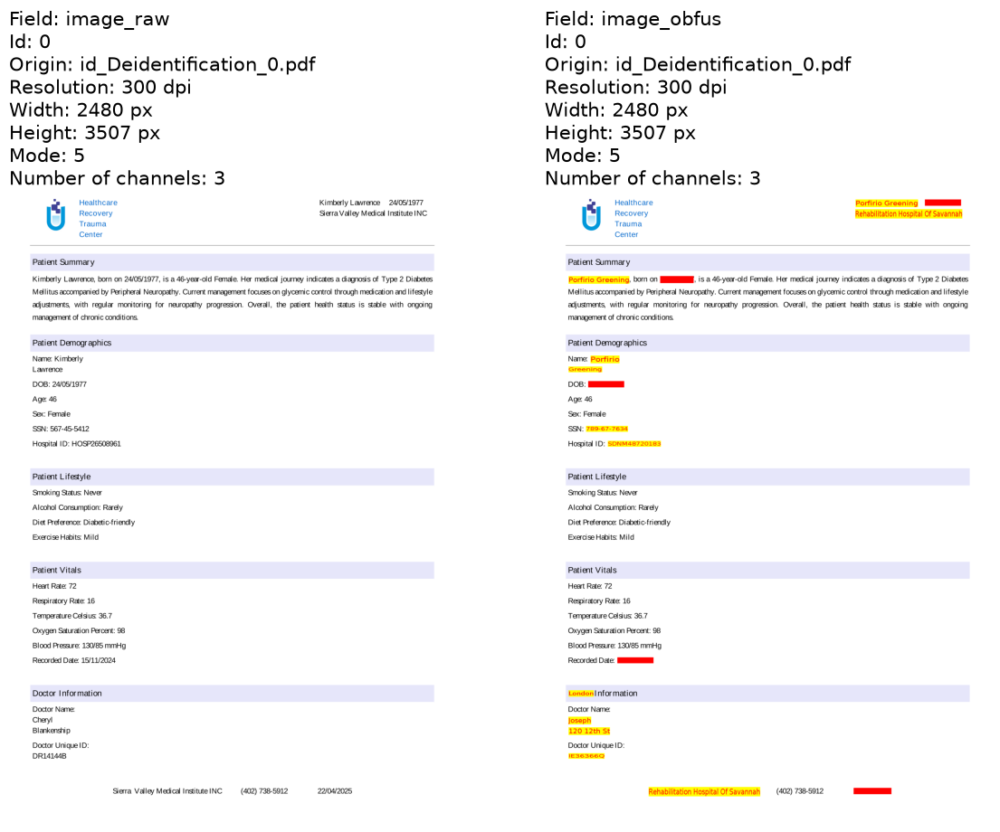

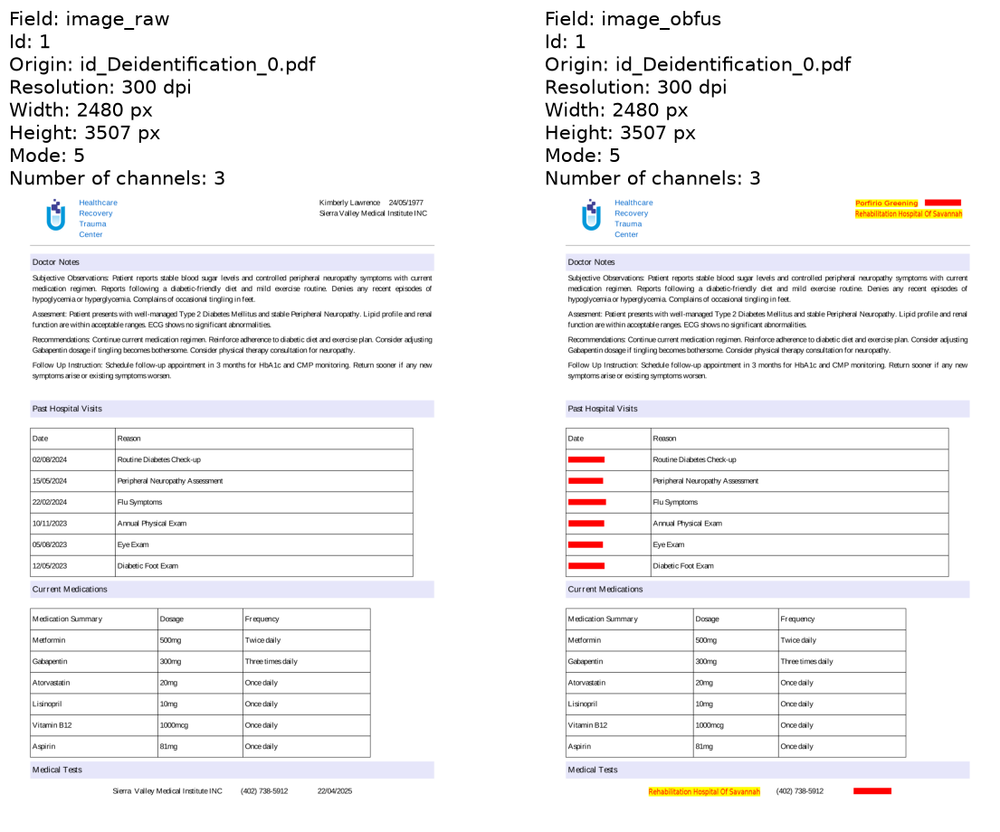

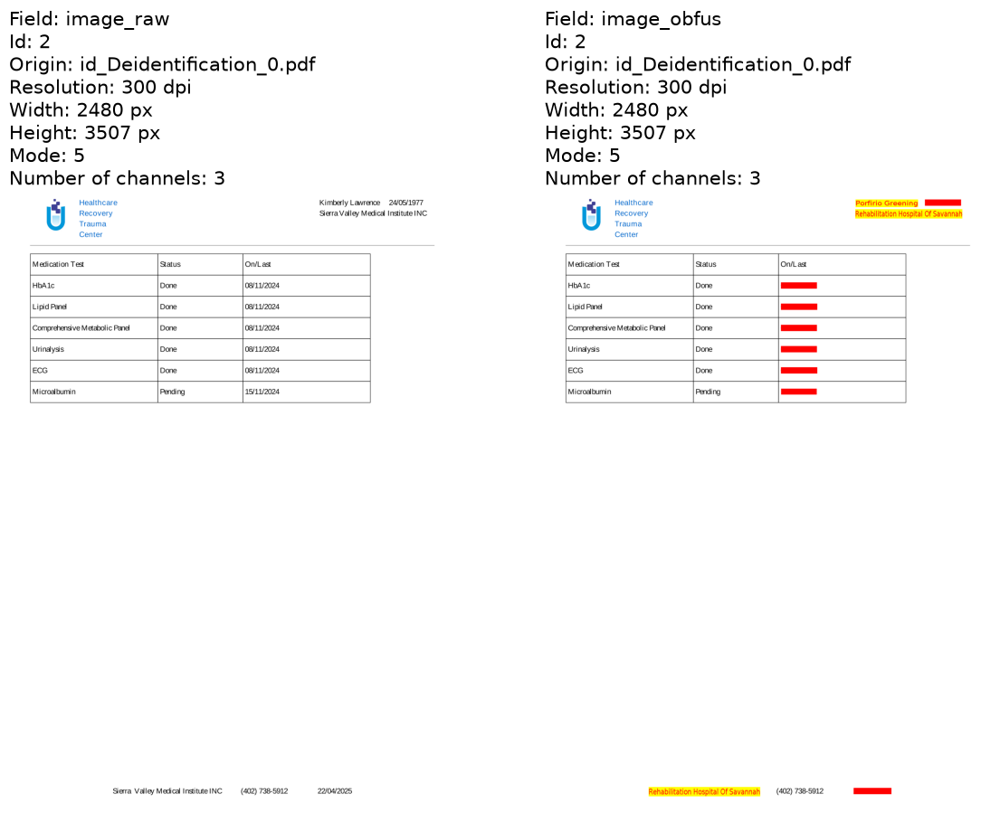

In [26]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

# 📄 Handling Medium-Complexity PDF Files  

When moving to **denser documents**, the challenges increase due to layout variety and added noise.  

---

## 🔹 Characteristics of Medium PDF Files  
- **Different Layouts**  
  - Multi-column sections  
  - Tables with merged cells  
  - Headers & footers with overlapping elements  

- **Added Noise**  
  - Ink bleed through pages  
  - Dirty screen effects  
  - Subtle background textures (e.g., scanned reports, faint grids, hospital letterheads)  

---

In [27]:
input_df = spark.read.format("binaryFile").load("./source_pdfs/Medium/PDF_Deid_Deidentification_Medium_0.pdf")

In [28]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["Date", "Coordinator For Healthplans", "Encounter Summary", "Chondroitin", "Paitnet"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(True) \
  .setFontStyle(FontStyle.PLAIN) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

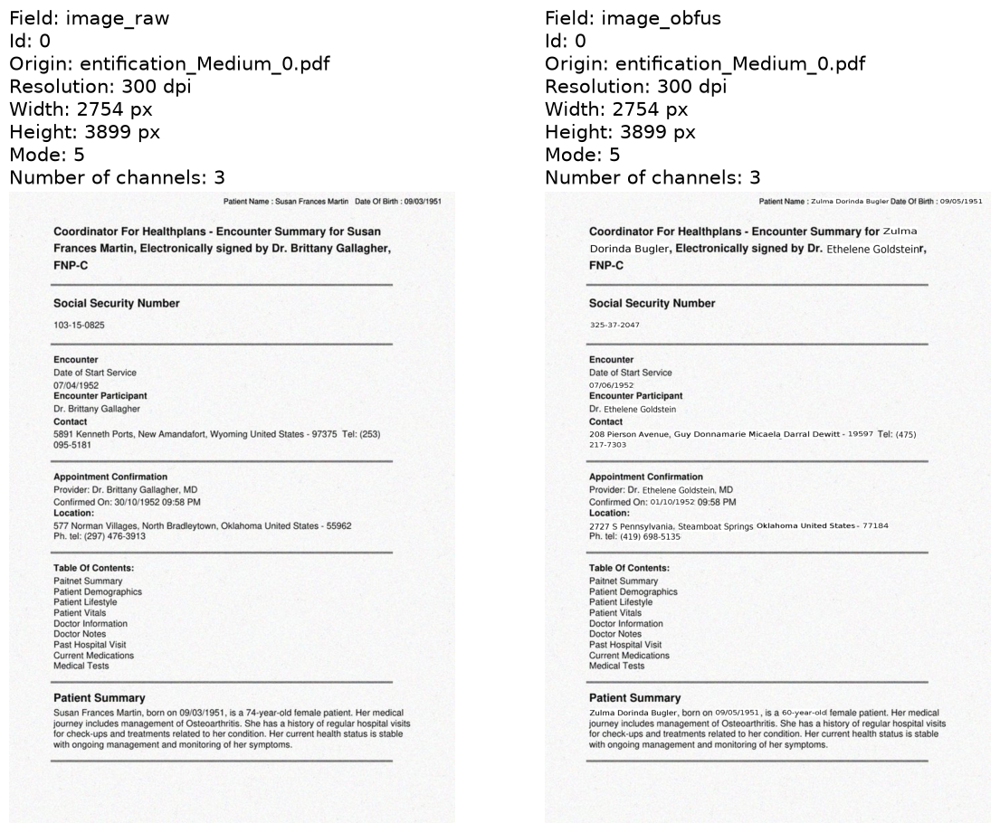

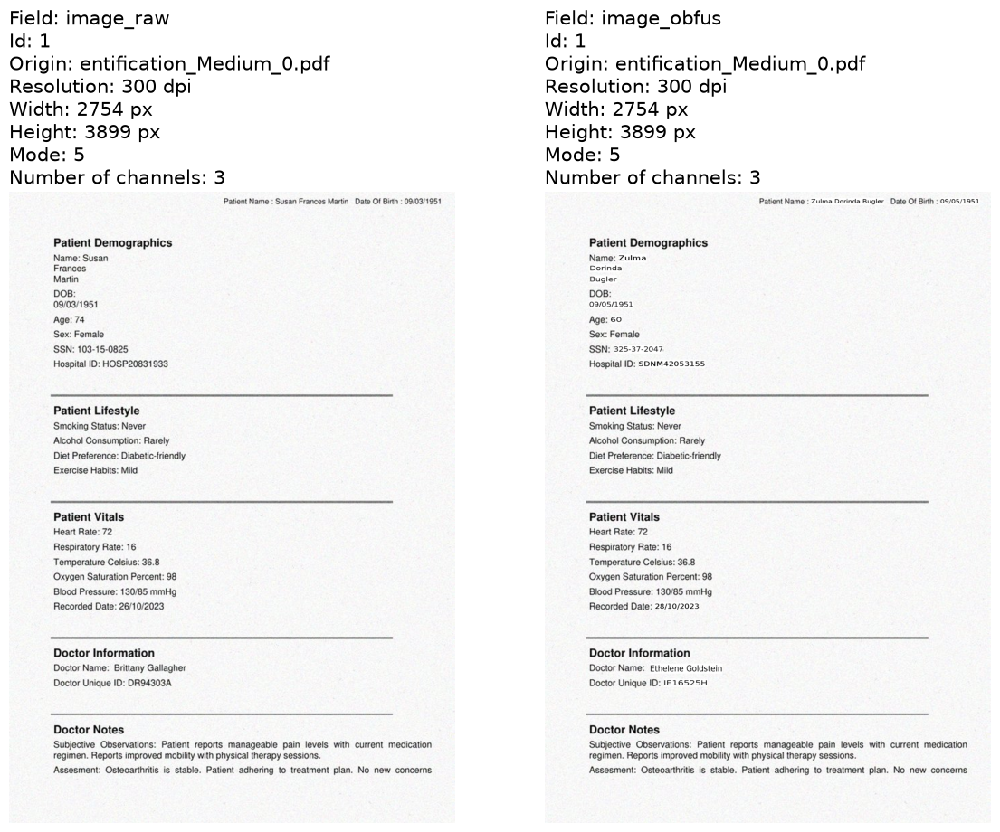

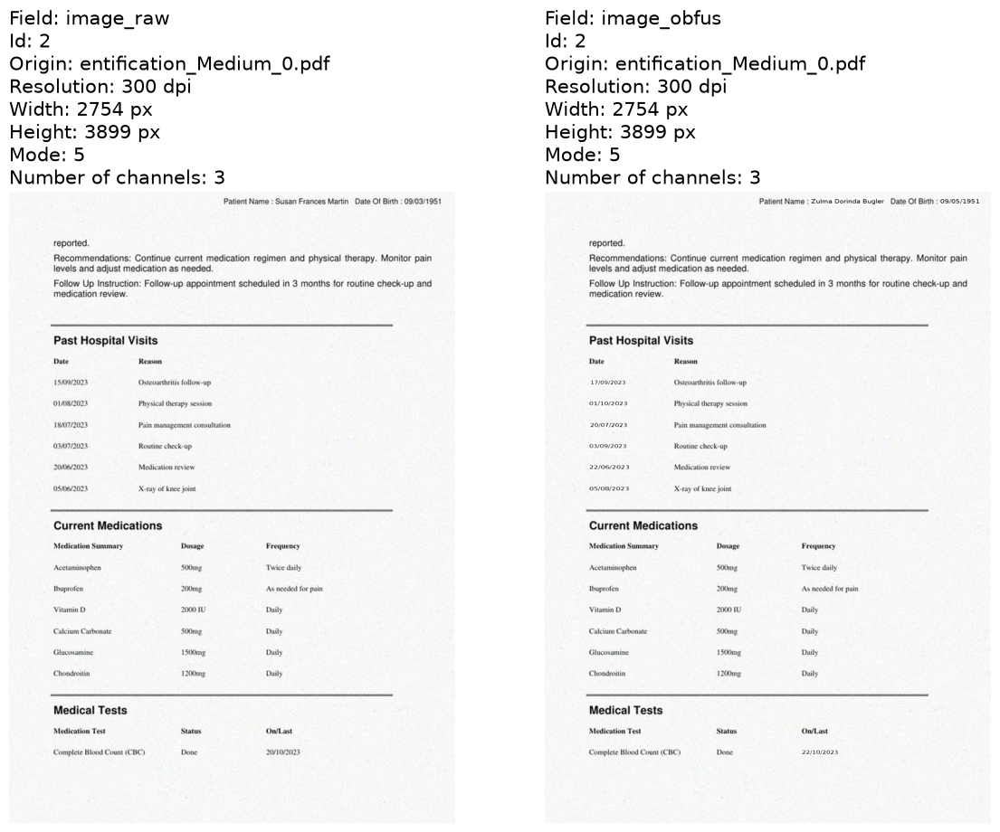

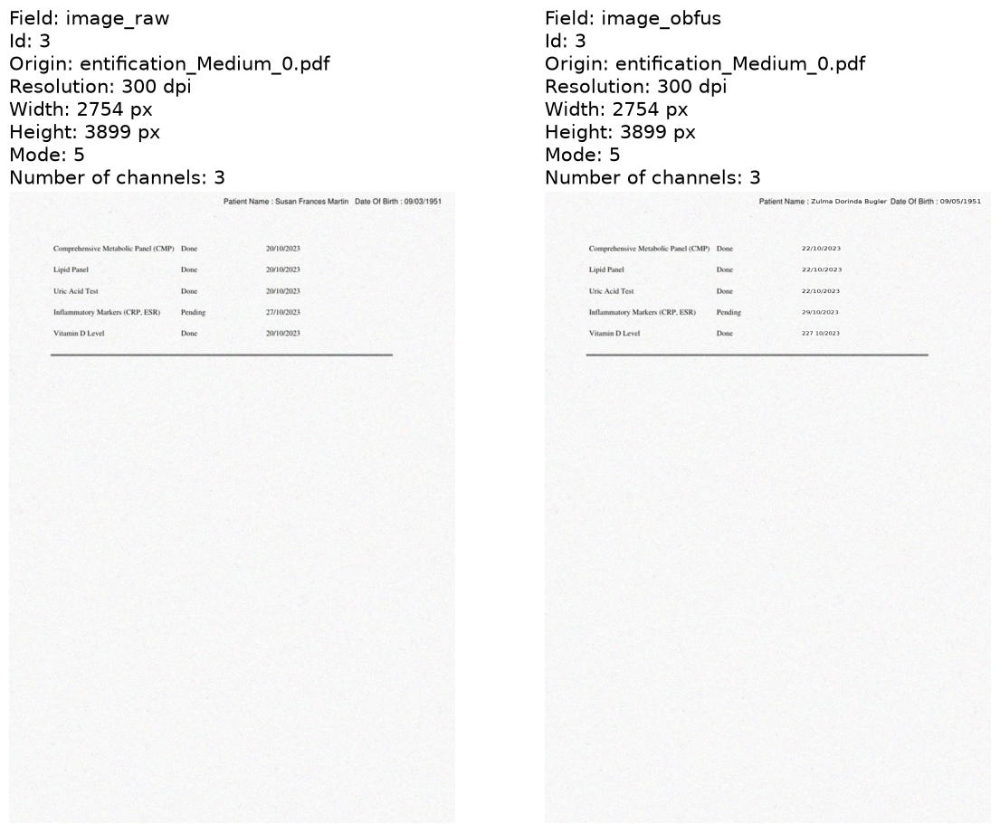

In [29]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

In [30]:
result.withColumn("res", F.explode(F.col("new_aux"))) \
    .select(F.col("res.result").alias("ObfuscatedResult"),
            F.length("res.result").alias("ObfuscatedLength"),
            F.col("res.metadata.originalChunk").alias("DetectedPhi"),
            F.length("res.metadata.originalChunk").alias("OriginalLength"),
            F.abs(F.col("ObfuscatedLength") - F.col("OriginalLength")).alias("LengthOffset"),
            F.col("res.metadata.entity").alias("EntityClass"),
            F.col("pagenum")) \
    .orderBy("pagenum").show(100, False)

+------------------------------------+----------------+-------------------------------------+--------------+------------+-----------+-------+
|ObfuscatedResult                    |ObfuscatedLength|DetectedPhi                          |OriginalLength|LengthOffset|EntityClass|pagenum|
+------------------------------------+----------------+-------------------------------------+--------------+------------+-----------+-------+
|Zulma Dorinda Bugler                |20              |Susan Frances Martin                 |20            |0           |PATIENT    |0      |
|09/05/1951                          |10              |09/03/1951                           |10            |0           |DATE       |0      |
|Zulma                               |5               |Susan                                |5             |0           |PATIENT    |0      |
|Dorinda Bugler                      |14              |Frances Martin                       |14            |0           |DOCTOR     |0      |
|Ethel

# 📄 Handling Hard-Complexity PDF Files  

Hard PDF files represent the **most challenging scenarios** due to their layout density and physical noise artifacts.  

---

## 🔹 Characteristics of Hard PDF Files  
- **Dense Layouts**  
  - Extremely **compact text on single lines** (minimal spacing).  
  - Multi-section pages with overlapping content.  
  - High word density leading to OCR segmentation errors.  

- **Severe Noise Factors**  
  - **Punch holes (left margin)** interfering with line detection.  
  - **Binder clips (right margin)** creating false dark regions.  
  - **Noise texturisation** across the page.  
  - **Moire patterns** (scanner/photocopy artifacts) distorting readability.  

---

In [31]:
input_df = spark.read.format("binaryFile").load("./source_pdfs/Hard/PDF_Deid_Deidentification_Hard_0.pdf")

In [32]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["SS", "Insurance Agent", "Date", "4"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(True) \
  .setFontStyle(FontStyle.PLAIN) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

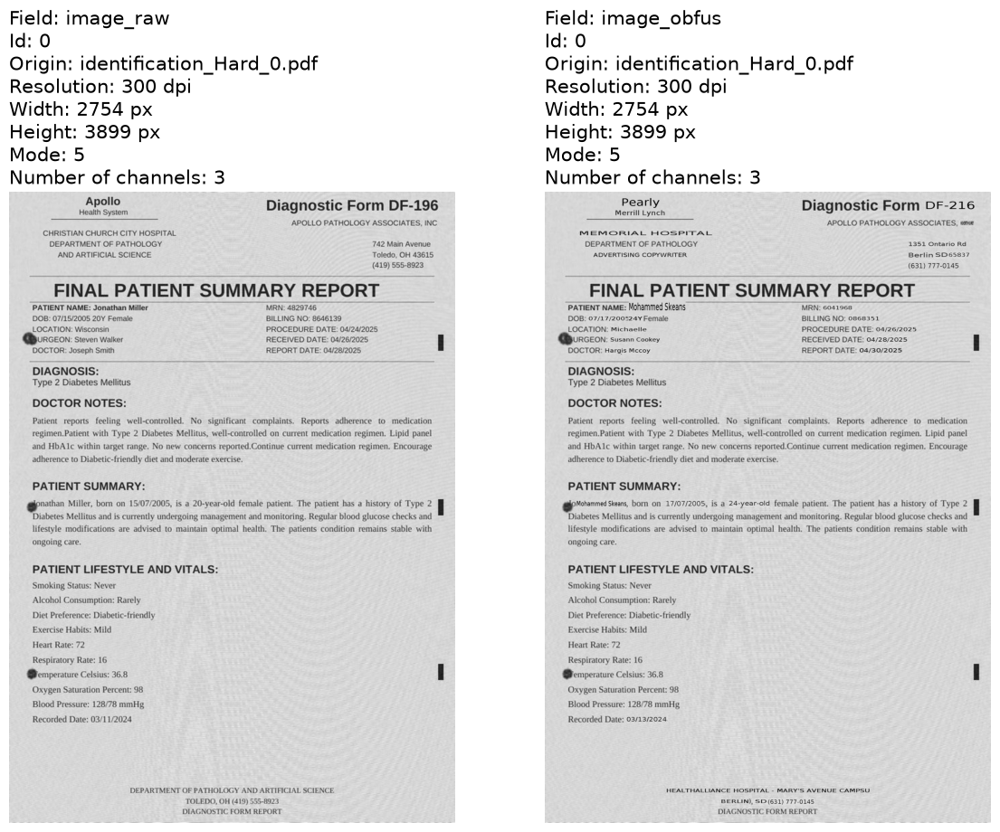

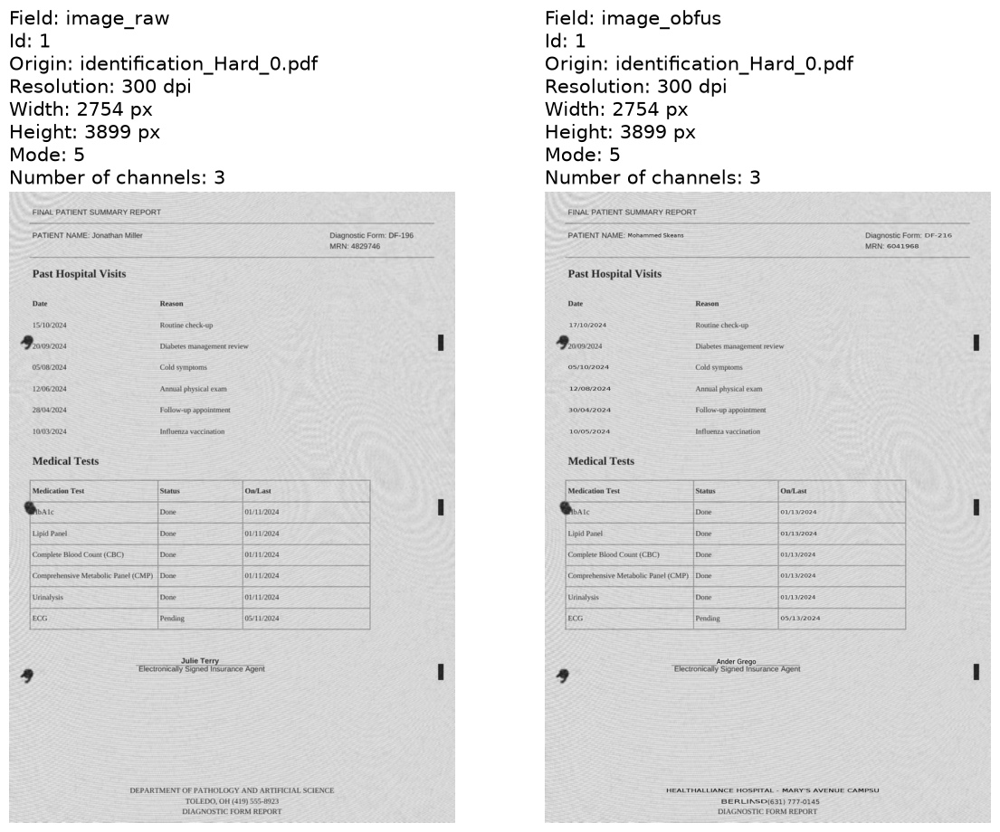

In [33]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

In [34]:
result.withColumn("res", F.explode(F.col("new_aux"))) \
    .select(F.col("res.result").alias("ObfuscatedResult"),
            F.length("res.result").alias("ObfuscatedLength"),
            F.col("res.metadata.originalChunk").alias("DetectedPhi"),
            F.length("res.metadata.originalChunk").alias("OriginalLength"),
            F.abs(F.col("ObfuscatedLength") - F.col("OriginalLength")).alias("LengthOffset"),
            F.col("res.metadata.entity").alias("EntityClass"),
            F.col("pagenum")) \
    .orderBy("pagenum").show(100, False)

+----------------------------------------------+----------------+----------------------------------------------+--------------+------------+-------------+-------+
|ObfuscatedResult                              |ObfuscatedLength|DetectedPhi                                   |OriginalLength|LengthOffset|EntityClass  |pagenum|
+----------------------------------------------+----------------+----------------------------------------------+--------------+------------+-------------+-------+
|Pearly                                        |6               |Apollo                                        |6             |0           |NAME         |0      |
|DF-216                                        |6               |DF-196                                        |6             |0           |DATE         |0      |
|Merrill Lynch                                 |13              |Health System                                 |13            |0           |ORGANIZATION |0      |
|HIGHSMITH-RAINEY MEMO

# 🧩 Obfuscation with Inpainting (when colors aren’t enough)

Sometimes **`setDynamicColor(True)`** or **`patchBackgroundColor`** / **`patchTextColor`** can fail:
- Noisy pixels around text
- Mixed/complex backgrounds where one color doesn’t fit all

In these cases, use **`ImageInpainting`** to *destroy text information while preserving the background*.

---

## 🔧 How `ImageInpainting` works

1. **Inputs**
   - Consumes detected **`text_regions`** from your text detector (e.g., `ImageTextDetector`/`ImageTextDetectorV2`)
   - Can also use **`positions`** from `ImageToText`

2. **Operation**
   - Removes / *inpaints* those regions, effectively erasing text while matching local background

3. **Tiling size**
   - Width  = `min(512, ImageWidth)`
   - Height = `min(512, ImageHeight)`

4. ⚡ **Performance tip**
   - Run on **GPU** for faster inference if available

---

## 🖼️ Pairing with ImageDrawRegions (post-inpainting)

After inpainting, you can still overlay patches/text for selective redact/obfuscate.  
Configure **`ImageDrawRegions`** as follows:

- **`setPatchImages(true)`** — enable patch rendering
- **`setInpaintedCol(...)`** — ensure the stage reads the *inpainted* image column


In [35]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["SS", "Insurance Agent", "Date", "4"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

inpainting_ann = ImageInpainting.pretrained("image_inpainting", "en", "clinical/ocr") \
    .setInputCol("image_raw") \
    .setOutputCol("image_inpainted") \
    .setOriginCol("path") \
    .setInputRegionsCol("positions") \
    .setWidth(512) \
    .setHeight(512) \
    .setUseGPU(False)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(True) \
  .setInpaintedCol("image_inpainted") \
  .setFontStyle(FontStyle.PLAIN) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(inpainting_ann)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

image_inpainting download started this may take some time.
Approximate size to download 181.2 MB


Download done! Loading the resource.


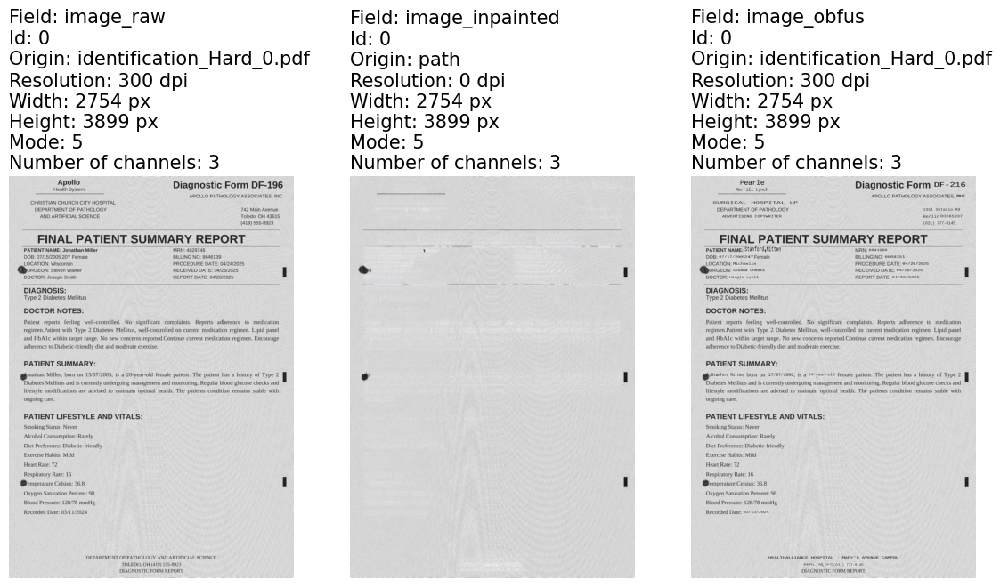

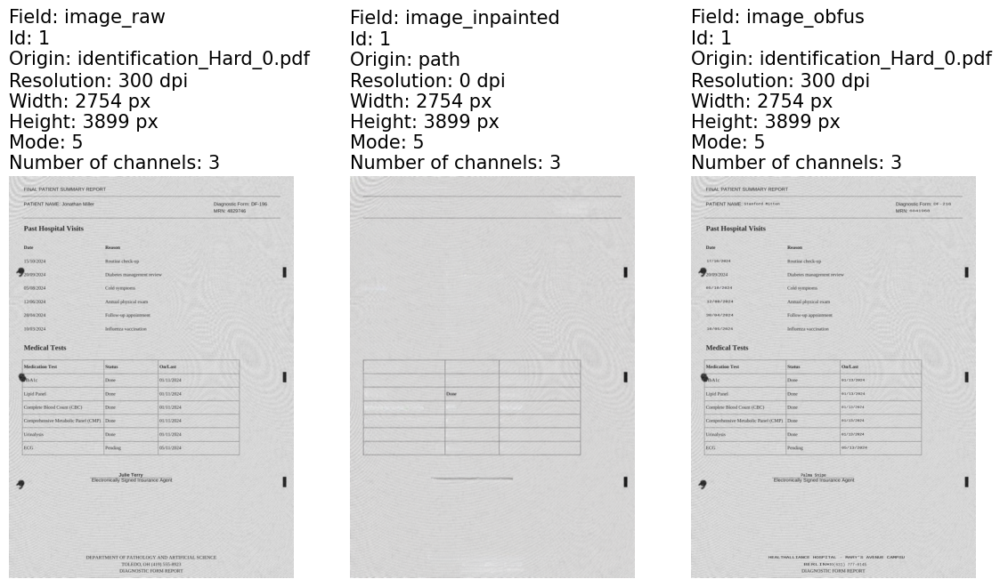

In [33]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_inpainted,image_obfus")

In [37]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["SS", "Insurance Agent", "Date", "4"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

text_detector = ImageTextDetector.pretrained("image_text_detector_mem_opt", "en", "clinical/ocr") \
    .setInputCol("image_raw") \
    .setOutputCol("text_regions") \
    .setScoreThreshold(0.7) \
    .setLinkThreshold(0.5) \
    .setWithRefiner(True) \
    .setTextThreshold(0.4) \
    .setSizeThreshold(-1) \
    .setUseGPU(False) \
    .setWidth(0)

inpainting_ann = ImageInpainting.pretrained("image_inpainting", "en", "clinical/ocr") \
    .setInputCol("image_raw") \
    .setOutputCol("image_inpainted") \
    .setOriginCol("path") \
    .setInputRegionsCol("text_regions") \
    .setWidth(512) \
    .setHeight(512) \
    .setUseGPU(False)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(True) \
  .setInpaintedCol("image_inpainted") \
  .setFontStyle(FontStyle.PLAIN) \
  .setOutputCol("image_obfus")

stages[0] = pdf_to_image
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(text_detector)
stages.append(inpainting_ann)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

image_text_detector_mem_opt download started this may take some time.
Approximate size to download 77.5 MB
image_text_detector_mem_opt download started this may take some time.
Approximate size to download 77.5 MB
Download done! Loading the resource.
image_inpainting download started this may take some time.


Approximate size to download 181.2 MB


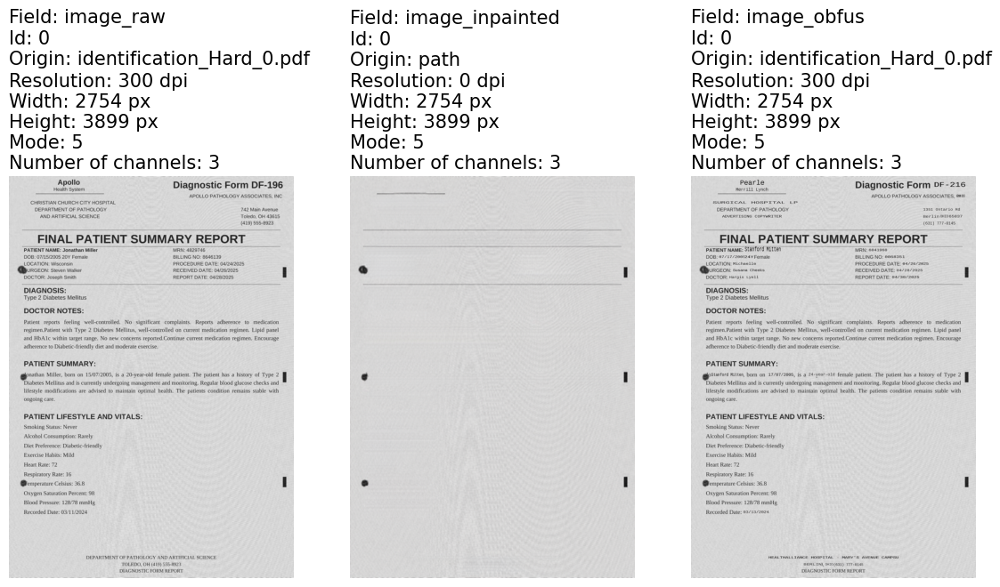

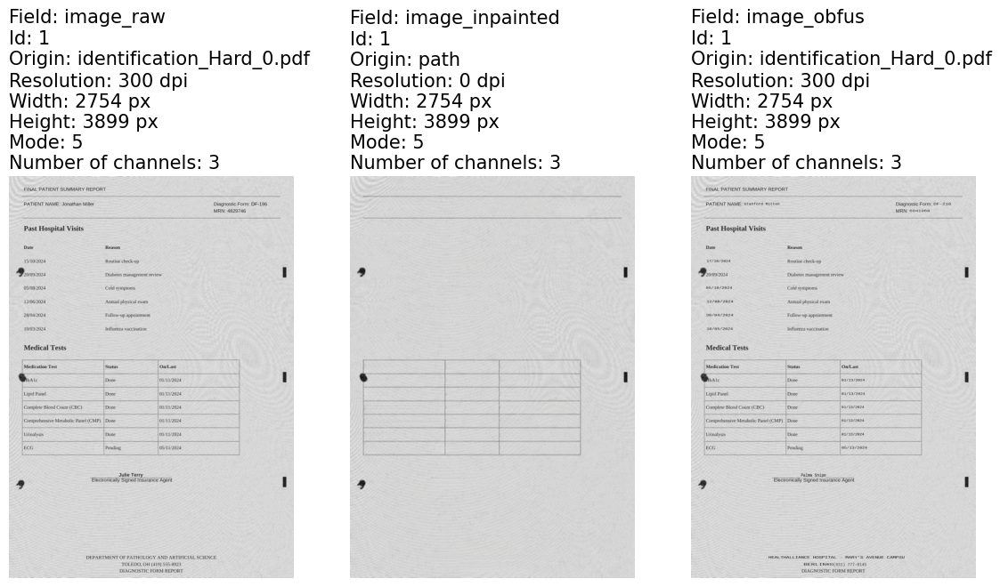

In [35]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_inpainted,image_obfus")

# 🎯 Style-Matched Obfuscation

With **`setPatchImages(True)`** the fake text is drawn with one font (**`setFontName`**), a guessed style and a dynamic color, so it rarely looks like the rest of the document, and on noisy scans parts of the original text can stay visible under the patch.

**`setStyleMatching(True)`** replaces each obfuscated box so that the new text looks like the original:

- Detects the **font, size, weight, width and ink color** of the original text.
- Removes the original text, keeping the background of the document.
  - If **`setInpaintedCol(...)`** is set, the inpainted image is used as the background.
- Draws the obfuscated text with the same style.

---

## 🔤 Fonts

- A catalog of open fonts is bundled: **Liberation Sans / Serif / Mono** and **Carlito** (metric compatible with Arial, Times New Roman, Courier New and Calibri).
- **`setStyleFonts([...])`** adds more fonts to the catalog: installed font names (e.g. `"Tahoma"`) or paths to `.ttf` / `.otf` files. No training is needed.

⚠️ **Note**: `setStyleMatching` is **off by default**. **`setFontName`**, **`setFontStyle`** and the color settings are not used for the boxes it replaces. Redaction (**`setRedactionEntityList`**) and **`setBlackList`** work as before.

In [36]:
stages = obfuscation_pipeline.model.stages[:-5].copy()

pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

chunkerFilter = ChunkFilterer() \
  .setInputCols(["sentence", "merged_ner_chunk"]) \
  .setOutputCol("filtered_chunks") \
  .setCriteria("isin") \
  .setBlackList(["SS", "Insurance Agent", "Date", "4"])

deid_obfuscated = DeIdentification() \
    .setInputCols(["sentence", "token", "filtered_chunks"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setKeepMonth(True) \
    .setKeepYear(True) \
    .setObfuscateDate(True) \
    .setSameEntityThreshold(0.7) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setReturnEntityMappings(True) \
    .setDays(2) \
    .setMappingsColumn("aux") \
    .setIgnoreRegex(True) \
    .setGroupByCol("path") \
    .setRegion("us") \
    .setSeed(40) \
    .setConsistentObfuscation(True) \
    .setChunkMatching(matcherWhitelist)

cleaner = NerOutputCleaner() \
    .setInputCol("aux") \
    .setOutputCol("new_aux") \
    .setOutputNerCol("positions_ner")

position_finder = PositionFinder() \
  .setInputCols("positions_ner") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setStyleMatching(True) \
  .setOutputCol("image_obfus")

# Optional: extend the font catalog with installed fonts or font files
# draw_regions.setStyleFonts(["Tahoma", "/path/to/MyFont-Regular.ttf"])

stages[0] = pdf_to_image
stages.append(chunkerFilter)
stages.append(deid_obfuscated)
stages.append(cleaner)
stages.append(position_finder)
stages.append(draw_regions)

obfuscation_updated_pipeline = Pipeline(stages=stages)

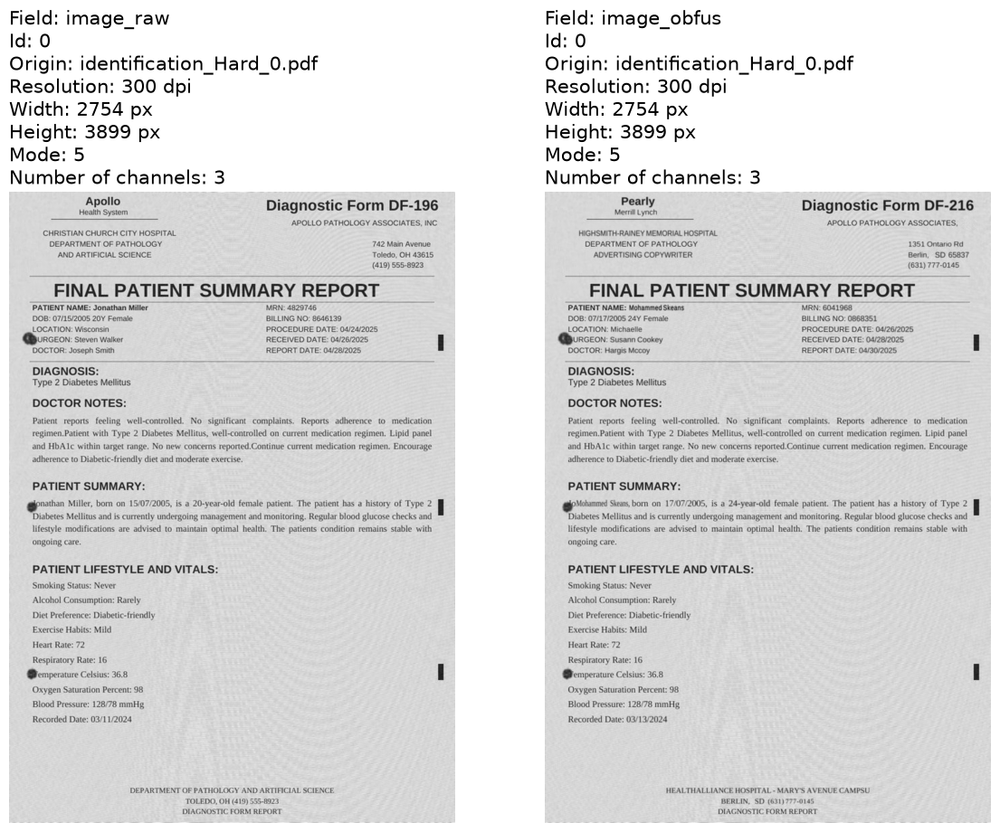

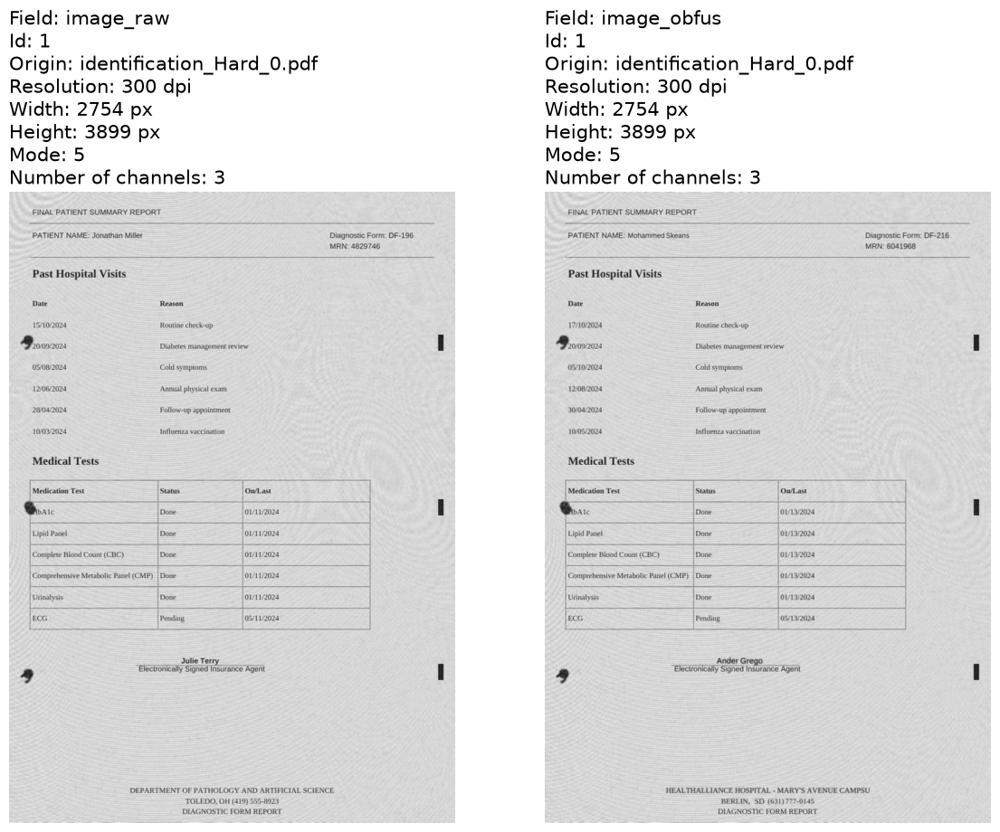

In [37]:
result = obfuscation_updated_pipeline.fit(input_df).transform(input_df).cache()

display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

### 📄 Easy and Medium Files

The same pipeline works for the other documents; only the blacklist of the `ChunkFilterer` changes.

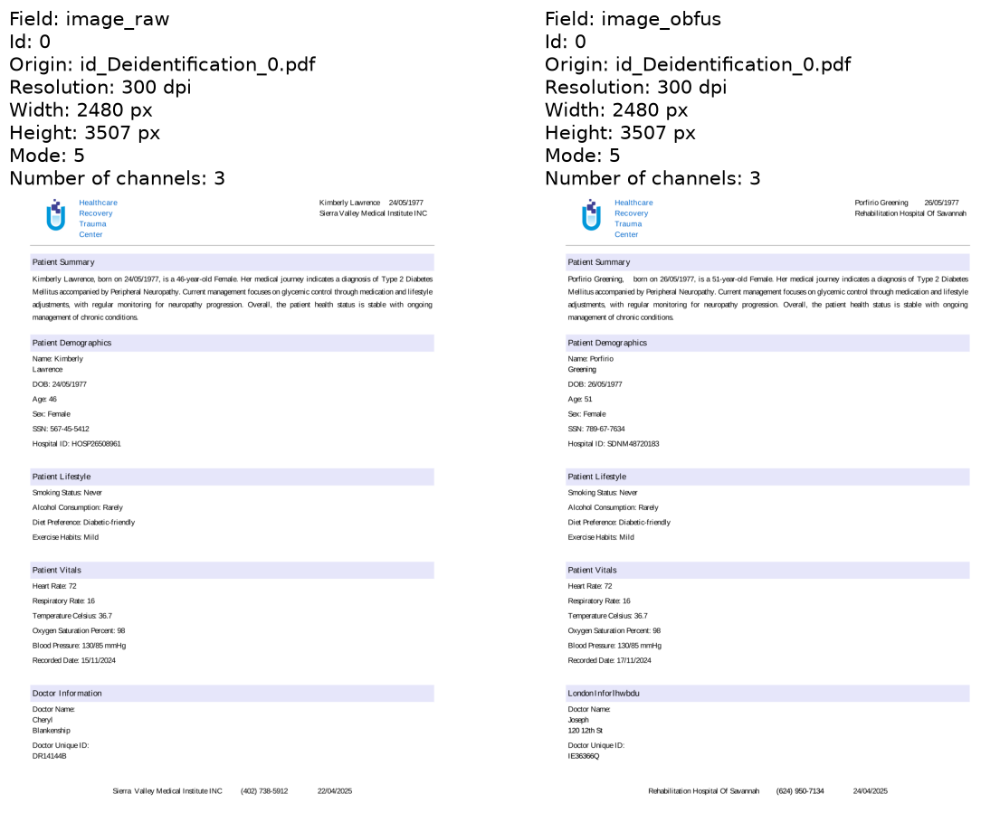

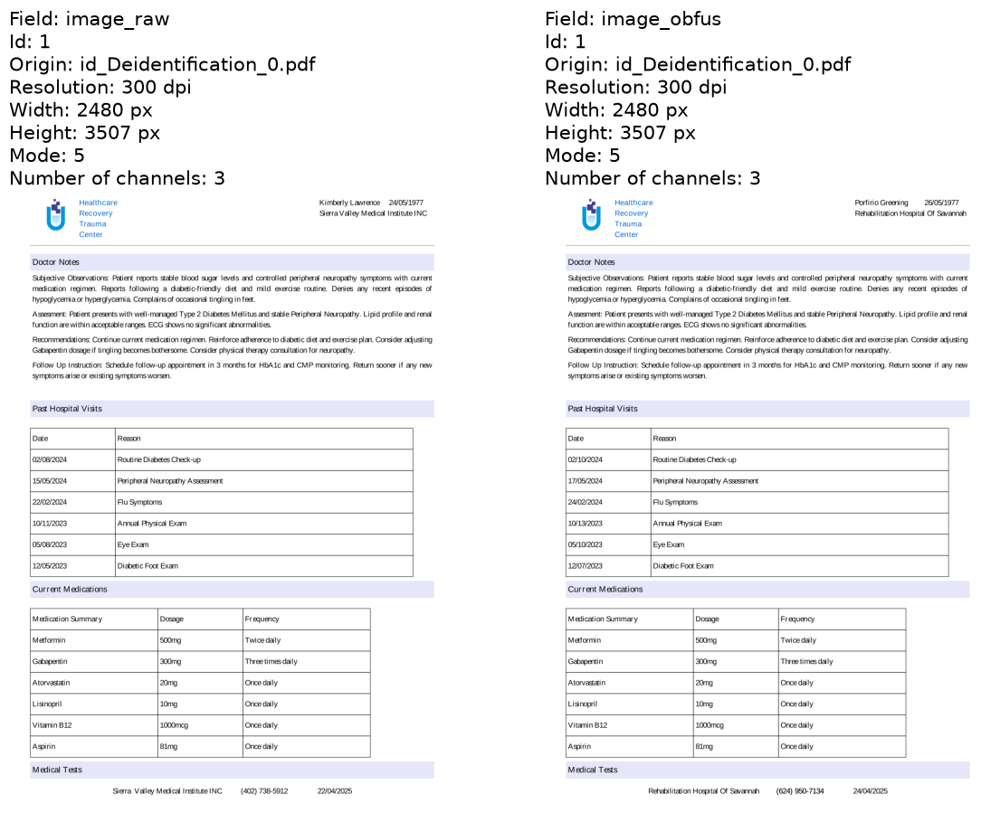

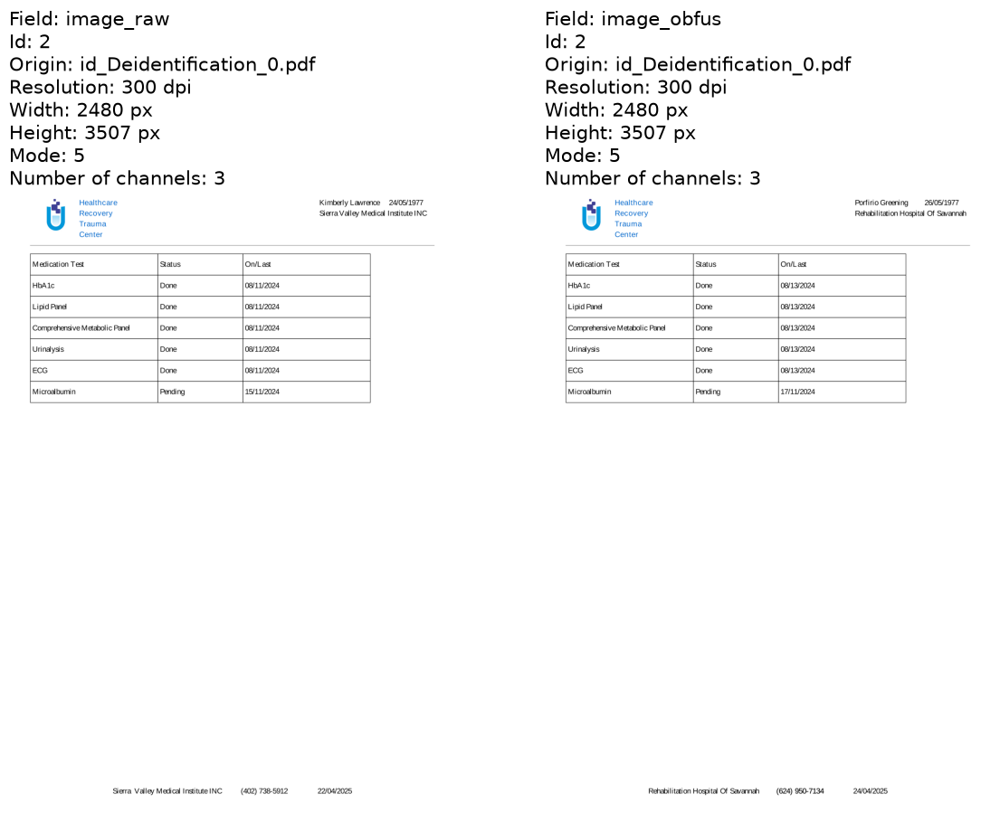

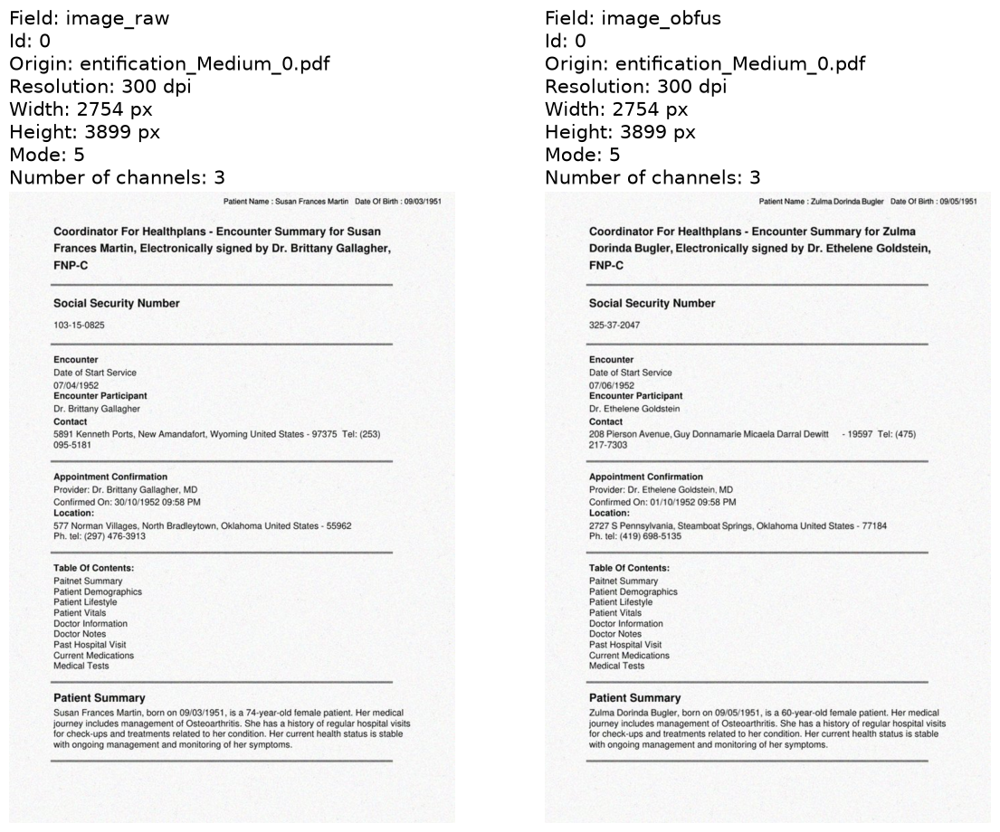

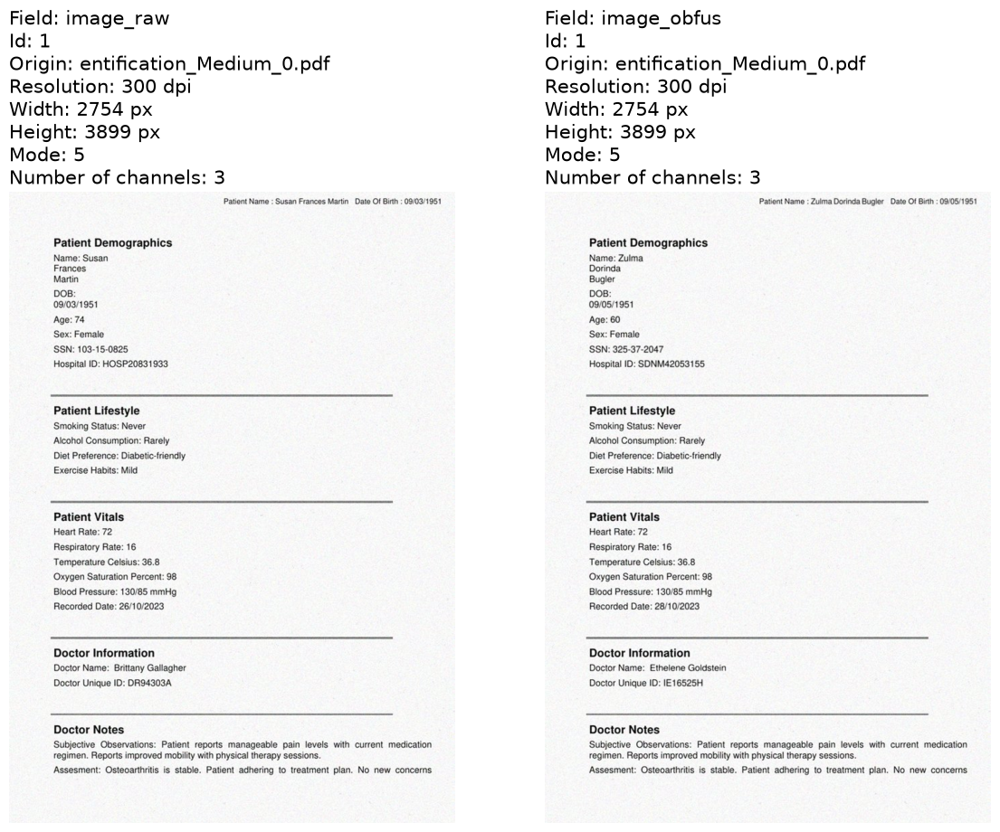

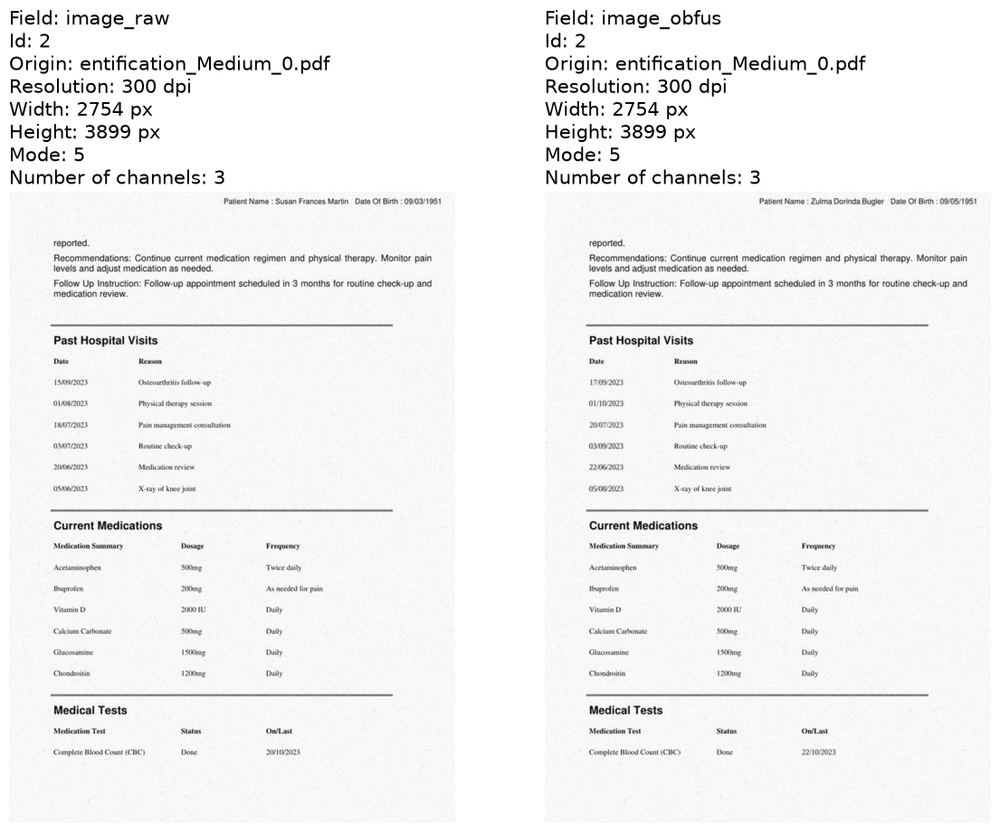

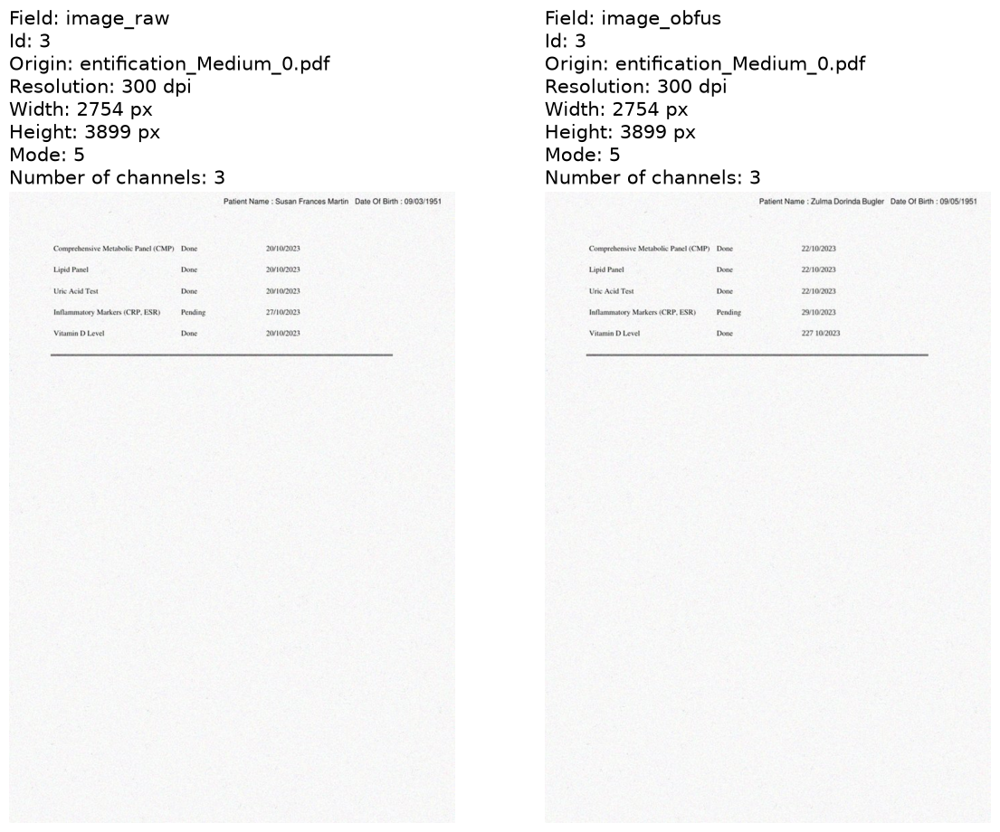

In [38]:
samples = [
    ("./source_pdfs/Easy/PDF_Deid_Deidentification_0.pdf", ["Date", "Gabapentin", "Metformin", "0"]),
    ("./source_pdfs/Medium/PDF_Deid_Deidentification_Medium_0.pdf",
     ["Date", "Coordinator For Healthplans", "Encounter Summary", "Chondroitin", "Paitnet"]),
]

for path, black_list in samples:
    sample_df = spark.read.format("binaryFile").load(path)
    chunkerFilter.setBlackList(black_list)
    result = obfuscation_updated_pipeline.fit(sample_df).transform(sample_df).cache()
    display_images_horizontal(result.orderBy(F.col("pagenum")), "image_raw,image_obfus")

# 🖼️ Image Obfuscation with Pretrained Pipelines  

You can convert any of the **PDF Pretrained Pipelines** to work with **Images** instead of PDFs.  

---

## 🔹 How to Adapt the Pipeline  

1. **Replace**  
   - Swap out the **`PdfToImage`** stage with **`BinaryToImage`**.  

2. **Remove**  
   - Drop the last stage **`ImageToPDF`**, since we want to save the **images** rather than reconvert them back to PDF.  

3. **Output Column Consistency**  
   - Ensure the **`outputCol`** of `BinaryToImage` is the **same as in the original `PdfToImage` stage**.  
   - You can check the `outputCol` name in the `PdfToImage` stage and reuse it for `BinaryToImage`.  

---

In [39]:
obfuscation_pipeline.model.stages

[PdfToImage_3039dbc55d70,
 ImageToText_e47a60ca0cbf,
 DocumentAssembler_47aaa7f19fed,
 SentenceDetectorDLModel_6bafc4746ea5,
 REGEX_TOKENIZER_e1689c9bc262,
 WORD_EMBEDDINGS_MODEL_9004b1d00302,
 MedicalNerModel_9d4a08b1c03d,
 NerConverter_f230dec390db,
 CONTEXTUAL-PARSER_c654a34a3fa4,
 CONTEXTUAL-PARSER_33af26b2fdc0,
 CONTEXTUAL-PARSER_1b2769552347,
 CONTEXTUAL-PARSER_07bff3c2b284,
 CONTEXTUAL-PARSER_96b9d29769eb,
 CONTEXTUAL-PARSER_7aefd98e984c,
 ENTITY_EXTRACTOR_2ddfc4744b44,
 CONTEXTUAL-PARSER_99792b93398d,
 REGEX_MATCHER_2b137485db5e,
 CONTEXTUAL-PARSER_30dc43a095c1,
 CONTEXTUAL-PARSER_f64d354f0266,
 CONTEXTUAL-PARSER_72e20622d44a,
 CONTEXTUAL-PARSER_563cfd5f905d,
 REGEX_MATCHER_52d38a3643c9,
 MERGE_b0a322ec2787,
 MERGE_97a646c7a333,
 XLM_ROBERTA_EMBEDDINGS_b8a75c006754,
 MedicalNerModel_59183c57aedb,
 NER_CONVERTER_c48b64fa3415,
 PretrainedZeroShotNER_ca8c4dfe310f,
 NER_CONVERTER_1e400595b6da,
 PretrainedZeroShotNER_5f30ab9002f1,
 NER_CONVERTER_2eba5de8da64,
 MERGE_107935ba3a49,
 D

In [40]:
pdf_to_image = obfuscation_pipeline.model.stages[0]
pdf_to_image.getOrDefault(pdf_to_image.getParam("outputCol"))

'image_raw'

In [41]:
# Use PdfToImage to extract Images from PDF.
pdf_to_image = PdfToImage() \
  .setInputCol("content") \
  .setSplitNumBatch(10) \
  .setResolution(400) \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR) \
  .setSplittingStategy(SplittingStrategy.FIXED_NUMBER_OF_PARTITIONS)

# Call PDF To Image
images = pdf_to_image.transform(input_df)

# Extract the first page and convert to image, can be repurposed to save image to disk.
image_dict = images.filter(F.col("pagenum") == 0).select("image_raw").collect()[0].asDict()["image_raw"]
mode = image_dict["mode"]
image = to_pil_image(image_dict, mode)

# Save to Temporary Location
import tempfile

with tempfile.NamedTemporaryFile(delete=False, suffix=".png") as tmp_file:
    image.save(tmp_file.name, format="PNG")
    print(f"Image saved at: {tmp_file.name}")

Image saved at: /tmp/tmpft5etnjb.png


In [42]:
stages = obfuscation_pipeline.model.stages[:-3].copy()

binaryToImage = BinaryToImage() \
  .setInputCol("content") \
  .setOutputCol("image_raw") \
  .setImageType(ImageType.TYPE_3BYTE_BGR)

position_finder = PositionFinder() \
  .setInputCols("merged_ner_chunk") \
  .setOutputCol("coordinates") \
  .setPageMatrixCol("positions") \
  .setSmoothCoordinates(True)

draw_regions = ImageDrawRegions() \
  .setInputCol("image_raw") \
  .setInputRegionsCol("coordinates") \
  .setInputChunkMappingCol("new_aux") \
  .setPatchImages(True) \
  .setFontName("SansSerif") \
  .setDynamicColor(True) \
  .setFontStyle(FontStyle.BOLD) \
  .setOutputCol("image_obfus")

stages[0] = binaryToImage
stages.append(position_finder)
stages.append(draw_regions)

deidentification_image_pipe = PipelineModel(stages=stages)

Estimating resolution as 630


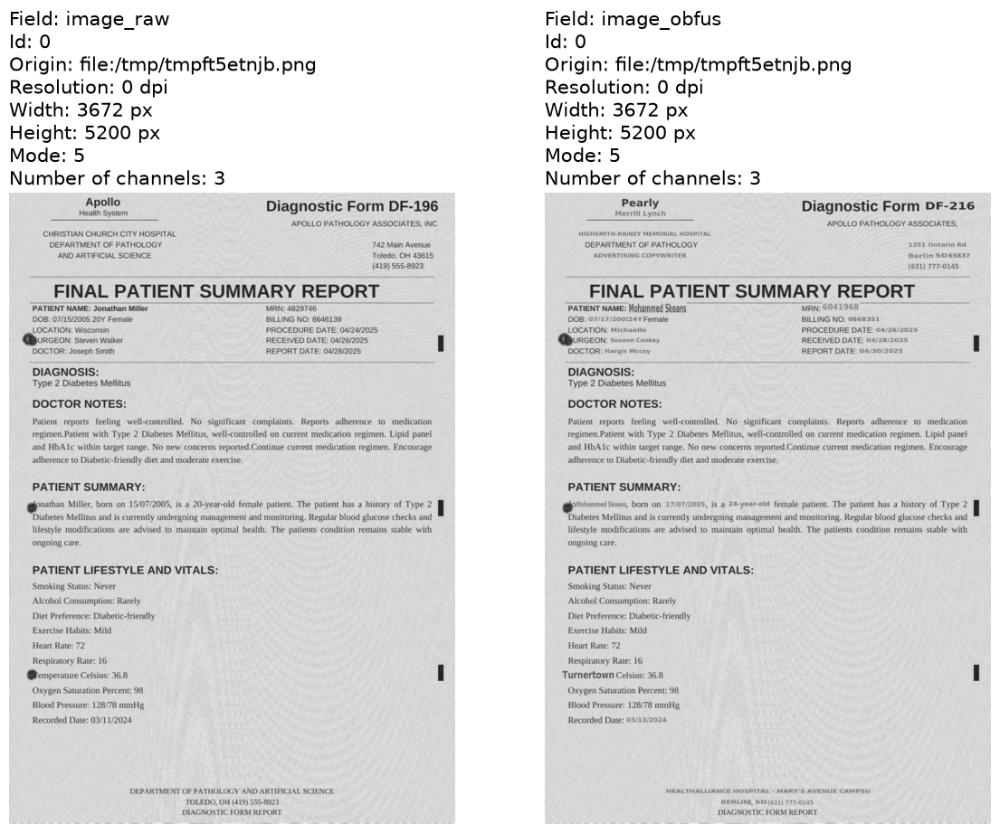

In [43]:
input_df = spark.read.format("binaryFile").load(tmp_file.name)
result = deidentification_image_pipe.transform(input_df).cache()

display_images_horizontal(result, "image_raw,image_obfus")

In [44]:
result.withColumn("res", F.explode(F.col("new_aux"))) \
    .select(F.col("res.result").alias("ObfuscatedResult"),
            F.length("res.result").alias("ObfuscatedLength"),
            F.col("res.metadata.originalChunk").alias("DetectedPhi"),
            F.length("res.metadata.originalChunk").alias("OriginalLength"),
            F.abs(F.col("ObfuscatedLength") - F.col("OriginalLength")).alias("LengthOffset"),
            F.col("res.metadata.entity").alias("EntityClass"),
            F.col("pagenum")) \
    .orderBy("pagenum").show(100, False)

+----------------------------------------------+----------------+----------------------------------------------+--------------+------------+-------------+-------+
|ObfuscatedResult                              |ObfuscatedLength|DetectedPhi                                   |OriginalLength|LengthOffset|EntityClass  |pagenum|
+----------------------------------------------+----------------+----------------------------------------------+--------------+------------+-------------+-------+
|Pearly                                        |6               |Apollo                                        |6             |0           |NAME         |0      |
|Merrill Lynch                                 |13              |Health System                                 |13            |0           |ORGANIZATION |0      |
|DF-216                                        |6               |DF-196                                        |6             |0           |DATE         |0      |
|HIGHSMITH-RAINEY MEMO

In [45]:
tmp_file.close()